# Assignment 13 --- Prompt-guided animal body-part segmentation, with and without a VLM

**Md. Shoaib Abdullah Khan · ID: 2010976135**

The task is a system that takes **an animal image and a natural-language prompt** (e.g. *"Show the ears of this
cat"*), finds and segments the requested body part, shows it isolated, and describes its appearance and biological
function. Two systems are built and compared on the same images and prompts.

| Assignment part | What is built | Where |
|---|---|---|
| **A** — without a VLM | keyword + text-embedding prompt parser → **YOLO11** animal detector → **YOLO11-seg part detector fine-tuned on PASCAL-Part** → **SAM 2** → predefined description + measured colour/size | §3 |
| **B** — with a VLM | **Qwen2.5-VL-3B** reads the image and prompt, locates the part → **Grounding DINO** refines the boxes → **SAM 2** → Qwen2.5-VL writes a context-aware description | §4 |
| UI | one **Gradio** app running both systems side by side (`app.py`) | §5 |
| **C** — comparison | same images and prompts for both systems; IoU / Dice, prompt following, description quality, compute | §6–§7 |

**Data.** *PASCAL-Part* (VOC 2010 images with part masks for bird, cat, cow, dog, horse and sheep) trains System A's
part detector (VOC *train* split) and provides a held-out test set with ground-truth masks (VOC *val* split) for
IoU / Dice. The **five phone photographs** (three dogs, two cats) are the real-world test, with the same prompts
given to both systems.

## 0. Environment

Non-standard packages: `ultralytics` (YOLO11, SAM 2.1), `transformers` (Qwen2.5-VL, Grounding DINO),
`sentence-transformers` (text-only prompt embedding for System A) and `gradio` (UI). Gradio is pinned below 6,
because Gradio 6 pulls `huggingface_hub` 2.x, which breaks `transformers` 4.55.

In [1]:
# %pip install -q ultralytics "transformers>=4.49,<4.56" sentence-transformers "gradio<6" accelerate scipy opencv-python

In [2]:
import os, sys, json, time, math, random, warnings, subprocess, shutil, tarfile
os.environ["USE_TF"] = "0"; os.environ["TRANSFORMERS_NO_TF"] = "1"
from pathlib import Path
import numpy as np
import pandas as pd
import torch, cv2
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

ROOT = Path.cwd()                                  # .../Assignments/13
DATA, WEIGHTS, PHONE = ROOT / "data", ROOT / "weights", ROOT / "phone image"
OUT = ROOT / "outputs"
FIG, RES, PRED = OUT / "figures", OUT / "results", OUT / "predictions"
for d in (DATA / "raw", WEIGHTS, FIG, RES, PRED):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
import ultralytics, transformers, gradio
print(f"torch {torch.__version__} | ultralytics {ultralytics.__version__} | transformers {transformers.__version__} | gradio {gradio.__version__}")
print("GPU:", torch.cuda.get_device_name(0) if DEV == "cuda" else "none",
      f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)" if DEV == "cuda" else "")

torch 2.7.1+cu128 | ultralytics 8.3.162 | transformers 4.55.4 | gradio 5.50.0
GPU: NVIDIA GeForce RTX 5070 Ti (15.9 GB)


In [3]:
# plotting style -- fixed colour per system so A and B keep their colour in every figure
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
COL_A, COL_B, COL_B2, COL_B3 = PALETTE[0], PALETTE[1], PALETTE[3], PALETTE[2]
INK, INK2, INK3, GRIDC = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "figure.max_open_warning": 0})

def savefig(fig, name):
    fig.savefig(FIG / name)          # save but do not close, so the figure is also embedded in the notebook
    print("saved ->", (FIG / name).relative_to(ROOT))

---
# 1. Data

## 1.1 PASCAL-Part (download)

*PASCAL-Part* (Chen *et al.*, CVPR 2014) adds pixel masks for object parts to the PASCAL VOC 2010 images. The
annotations (81 MB) come from the authors' page, and the images (1.35 GB) from the VOC 2010 server. The connection
to both servers drops frequently, so the download below resumes with `curl -C -` until the file is complete, and
skips everything that is already on disk.

In [4]:
SOURCES = {
    "trainval.tar.gz": ("http://roozbehm.info/pascal-parts/trainval.tar.gz", 80_872_607),
    "VOCtrainval_03-May-2010.tar": ("http://host.robots.ox.ac.uk/pascal/VOC/voc2010/VOCtrainval_03-May-2010.tar", 1_345_040_896),
}
for fname, (url, size) in SOURCES.items():
    dst = DATA / "raw" / fname
    tries = 0
    while not dst.exists() or dst.stat().st_size < size:
        tries += 1
        subprocess.run(["curl", "-sL", "-C", "-", "--max-time", "600", "-o", str(dst), url])
        if tries > 200:
            raise RuntimeError(f"could not download {url}")
    print(f"{fname:32s} {dst.stat().st_size / 2**20:8.1f} MB  ok")

if not (DATA / "pascal_part" / "Annotations_Part").exists():
    with tarfile.open(DATA / "raw" / "trainval.tar.gz") as t:
        t.extractall(DATA / "pascal_part")
if not (DATA / "VOCdevkit" / "VOC2010" / "JPEGImages").exists():
    with tarfile.open(DATA / "raw" / "VOCtrainval_03-May-2010.tar") as t:
        t.extractall(DATA, members=[m for m in t.getmembers() if "/JPEGImages/" in m.name
                                    or m.name.endswith(("Main/train.txt", "Main/val.txt"))])
print("annotation files:", len(list((DATA / "pascal_part" / "Annotations_Part").glob("*.mat"))),
      "| VOC images:", len(list((DATA / "VOCdevkit" / "VOC2010" / "JPEGImages").glob("*.jpg"))))

trainval.tar.gz                      77.1 MB  ok
VOCtrainval_03-May-2010.tar        1282.7 MB  ok
annotation files: 10103 | VOC images: 11321


## 1.2 Shared code: part vocabulary, colour naming, SAM 2, metrics

Both systems use the same 15 part classes, the same SAM 2 wrapper and the same drawing and metric helpers, so any
difference between them comes from *how they understand the prompt and find the part*, not from different
segmentation back-ends.

* **Part vocabulary.** PASCAL-Part names left/right copies separately (`lear`, `rear`), and for horses, cows and
  sheep it splits each leg into upper and lower segments. These are merged into 15 classes: head, ear, eye, nose,
  muzzle, neck, torso, leg, paw, tail, beak, wing, foot, hoof and horn. `SPECIES_PARTS` records which species has which part.
* **SAM 2 wrapper.** SAM 2.1 (base) is prompted with boxes. It runs on a context crop around the boxes, because a small
  part in a 4000-pixel phone photo would otherwise be only a few pixels wide at SAM's 1024-pixel input.
* **Colour naming.** K-means in Lab colour space on the masked pixels, matched to named fur colours. System A uses it
  for its description, and Part C uses it to check whether a description's colour words are correct.

In [5]:
%%writefile bp_common.py
"""Shared pieces used by both systems: part ontology, colour naming, SAM 2 wrapper, metrics, drawing."""
import os, time, math, re
from pathlib import Path
import numpy as np
import cv2
from PIL import Image, ImageOps

os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("TRANSFORMERS_NO_TF", "1")

ROOT = Path(__file__).resolve().parent
WEIGHTS = ROOT / "weights"

# --------------------------------------------------------------------------------------------- ontology
SPECIES = ["bird", "cat", "cow", "dog", "horse", "sheep"]

# 15 merged part classes used everywhere (index = YOLO class id of the part model)
PARTS = ["head", "ear", "eye", "nose", "muzzle", "neck", "torso", "leg", "paw", "tail",
         "beak", "wing", "foot", "hoof", "horn"]

# which parts each species has in PASCAL-Part
SPECIES_PARTS = {
    "cat":   ["head", "ear", "eye", "nose", "neck", "torso", "leg", "paw", "tail"],
    "dog":   ["head", "ear", "eye", "nose", "muzzle", "neck", "torso", "leg", "paw", "tail"],
    "bird":  ["head", "eye", "beak", "neck", "torso", "wing", "leg", "foot", "tail"],
    "horse": ["head", "ear", "eye", "muzzle", "neck", "torso", "leg", "hoof", "tail"],
    "cow":   ["head", "ear", "eye", "muzzle", "neck", "torso", "leg", "horn", "tail"],
    "sheep": ["head", "ear", "eye", "muzzle", "neck", "torso", "leg", "horn", "tail"],
}

# plural / display names
PLURAL = {"head": "head", "ear": "ears", "eye": "eyes", "nose": "nose", "muzzle": "muzzle",
          "neck": "neck", "torso": "torso", "leg": "legs", "paw": "paws", "tail": "tail",
          "beak": "beak", "wing": "wings", "foot": "feet", "hoof": "hooves", "horn": "horns"}


def load_image(path_or_img):
    """RGB PIL image with EXIF orientation applied (phone photos are often stored rotated)."""
    im = path_or_img if isinstance(path_or_img, Image.Image) else Image.open(path_or_img)
    return ImageOps.exif_transpose(im).convert("RGB")


def limit_size(im, max_side=1600):
    """Large phone photos (4000 px) are shrunk once; every model resizes internally anyway."""
    s = max(im.size)
    if s <= max_side:
        return im, 1.0
    f = max_side / s
    return im.resize((round(im.width * f), round(im.height * f)), Image.LANCZOS), f


# --------------------------------------------------------------------------------------------- colour naming
# reference colours for animal fur / feathers, named in plain words
NAMED_COLOURS = {
    "black": (25, 25, 25), "dark grey": (80, 80, 80), "grey": (135, 135, 135), "light grey": (190, 190, 190),
    "white": (240, 240, 240), "cream": (235, 220, 185), "beige": (205, 180, 140), "tan": (195, 150, 100),
    "light brown": (165, 115, 70), "brown": (115, 75, 45), "dark brown": (65, 40, 25),
    "ginger": (210, 120, 50), "golden": (215, 170, 80), "reddish brown": (150, 65, 40),
    "pink": (225, 150, 150), "yellow": (230, 200, 60), "orange": (235, 140, 30), "red": (190, 40, 40),
    "green": (70, 130, 60), "blue": (60, 100, 180),
}
_NC_NAMES = list(NAMED_COLOURS)
_NC_LAB = cv2.cvtColor(np.uint8([[NAMED_COLOURS[n] for n in _NC_NAMES]]), cv2.COLOR_RGB2LAB)[0].astype(np.float32)


def colour_names(img_rgb, mask, k=3, min_share=0.2):
    """Dominant colour names of the masked pixels (k-means in Lab space). Returns [(name, share), ...]."""
    px = img_rgb[mask.astype(bool)]
    if len(px) < 20:
        return []
    if len(px) > 6000:
        px = px[np.random.default_rng(0).choice(len(px), 6000, replace=False)]
    lab = cv2.cvtColor(px.reshape(-1, 1, 3).astype(np.uint8), cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(np.float32)
    k = min(k, len(lab))
    _, lbl, cen = cv2.kmeans(lab, k, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0), 3,
                             cv2.KMEANS_PP_CENTERS)
    out = {}
    for c in range(k):
        share = float((lbl == c).mean())
        name = _NC_NAMES[int(np.argmin(((_NC_LAB - cen[c]) ** 2).sum(1)))]
        out[name] = out.get(name, 0) + share
    return sorted([(n, s) for n, s in out.items() if s >= min_share], key=lambda t: -t[1])


# --------------------------------------------------------------------------------------------- SAM 2 wrapper
class SAM2Segmenter:
    """Box-prompted SAM 2.1 (ultralytics). Runs on a context crop around the boxes so that small parts
    in large photos are seen at a useful resolution. Shared by both systems."""

    def __init__(self, weights="sam2.1_b.pt", device="cuda"):
        from ultralytics import SAM
        self.model = SAM(str(WEIGHTS / weights) if (WEIGHTS / weights).exists() else weights)
        self.device = device

    def __call__(self, img_rgb, boxes, context=0.6, min_side=256):
        H, W = img_rgb.shape[:2]
        full = np.zeros((H, W), bool)
        if len(boxes) == 0:
            return full, []
        b = np.asarray(boxes, float)
        x1, y1, x2, y2 = b[:, 0].min(), b[:, 1].min(), b[:, 2].max(), b[:, 3].max()
        cw, ch = x2 - x1, y2 - y1
        pad = max(context * max(cw, ch), (min_side - max(cw, ch)) / 2, 8)
        cx1, cy1 = int(max(0, x1 - pad)), int(max(0, y1 - pad))
        cx2, cy2 = int(min(W, x2 + pad)), int(min(H, y2 + pad))
        crop = np.ascontiguousarray(img_rgb[cy1:cy2, cx1:cx2, ::-1])          # ultralytics wants BGR
        bb = (b - [cx1, cy1, cx1, cy1]).tolist()
        res = self.model(crop, bboxes=bb, verbose=False, device=self.device)[0]
        inst = []
        if res.masks is not None:
            for m in res.masks.data.cpu().numpy().astype(bool):
                if m.shape != crop.shape[:2]:
                    m = cv2.resize(m.astype(np.uint8), (crop.shape[1], crop.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
                g = np.zeros((H, W), bool)
                g[cy1:cy2, cx1:cx2] = m
                inst.append(g)
                full |= g
        return full, inst


# --------------------------------------------------------------------------------------------- metrics
def iou_dice(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    s = pred.sum() + gt.sum()
    iou = inter / union if union else (1.0 if s == 0 else 0.0)
    dice = 2 * inter / s if s else 1.0
    return float(iou), float(dice)


def box_iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def nms_boxes(boxes, scores, thr=0.5):
    order = np.argsort(scores)[::-1]
    keep = []
    for i in order:
        if all(box_iou(boxes[i], boxes[j]) < thr for j in keep):
            keep.append(i)
    return keep


# --------------------------------------------------------------------------------------------- drawing
def overlay(img_rgb, mask, colour=(255, 40, 120), alpha=0.5, boxes=()):
    out = img_rgb.copy().astype(np.float32)
    m = mask.astype(bool)
    out[m] = out[m] * (1 - alpha) + np.array(colour) * alpha
    out = out.astype(np.uint8)
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lw = max(2, round(max(img_rgb.shape[:2]) / 400))
    cv2.drawContours(out, cnts, -1, colour, lw)
    for b in boxes:
        cv2.rectangle(out, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (255, 215, 0), lw)
    return out


def isolate(img_rgb, mask, bg=255, pad=0.08):
    """The isolated body part: everything outside the mask blanked, cropped to the part."""
    m = mask.astype(bool)
    if not m.any():
        return np.full((64, 64, 3), bg, np.uint8)
    out = np.full_like(img_rgb, bg)
    out[m] = img_rgb[m]
    ys, xs = np.where(m)
    H, W = m.shape
    p = int(pad * max(np.ptp(ys) + 1, np.ptp(xs) + 1))
    return out[max(0, ys.min() - p):min(H, ys.max() + p + 1), max(0, xs.min() - p):min(W, xs.max() + p + 1)]


class Timer:
    def __init__(self):
        self.t = {}

    def __call__(self, name):
        timer = self

        class _T:
            def __enter__(s):
                import torch
                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                s.t0 = time.perf_counter()

            def __exit__(s, *a):
                import torch
                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                timer.t[name] = timer.t.get(name, 0) + time.perf_counter() - s.t0
        return _T()

Overwriting bp_common.py


## 1.3 Loading PASCAL-Part and building System A's training set

In [6]:
%%writefile bp_data.py
"""PASCAL-Part loading, part-class merging, YOLO-seg dataset building and test-set selection."""
import re, json, random
from pathlib import Path
import numpy as np
import cv2
import scipy.io as sio
from PIL import Image
from bp_common import PARTS, SPECIES, SPECIES_PARTS

ROOT = Path(__file__).resolve().parent
DATA = ROOT / "data"
ANNO = DATA / "pascal_part" / "Annotations_Part"
VOC = DATA / "VOCdevkit" / "VOC2010"


def merge_key(species, raw):
    """Raw PASCAL-Part part name -> (merged class, instance key). Left/right copies stay separate instances;
    upper+lower segments of the same leg are merged into one 'leg' instance."""
    if raw in ("head", "nose", "muzzle", "neck", "torso", "tail", "beak"):
        return raw, raw
    if raw in ("lear", "rear"):
        return "ear", raw
    if raw in ("leye", "reye"):
        return "eye", raw
    if raw in ("lhorn", "rhorn"):
        return "horn", raw
    if raw in ("lwing", "rwing"):
        return "wing", raw
    if raw in ("lfoot", "rfoot"):
        return "foot", raw
    if raw in ("lleg", "rleg"):                                  # bird legs
        return "leg", raw
    m = re.fullmatch(r"([lr][fb])(pa|ho|leg|lleg|uleg)", raw)    # e.g. lfpa, rbho, lfleg, rblleg
    if m:
        side, kind = m.groups()
        if kind == "pa":
            return "paw", side + "pa"
        if kind == "ho":
            return "hoof", side + "ho"
        return "leg", side + "leg"
    return None, None


def load_anno(img_id):
    """List of animal objects: {'species','mask','parts': {part: [instance masks]}}."""
    a = sio.loadmat(str(ANNO / f"{img_id}.mat"))["anno"][0, 0]["objects"]
    objs = []
    for o in a[0]:
        sp = str(o["class"][0])
        if sp not in SPECIES:
            continue
        inst = {}
        for p in (o["parts"][0] if o["parts"].size else []):
            cls, key = merge_key(sp, str(p["part_name"][0]))
            if cls is None:
                continue
            m = p["mask"].astype(bool)
            inst[(cls, key)] = inst.get((cls, key), np.zeros_like(m)) | m
        parts = {}
        for (cls, _), m in inst.items():
            parts.setdefault(cls, []).append(m)
        objs.append({"species": sp, "mask": o["mask"].astype(bool), "parts": parts})
    return objs


def voc_split(name):
    return [l.strip() for l in open(VOC / "ImageSets" / "Main" / f"{name}.txt") if l.strip()]


def image_path(img_id):
    return VOC / "JPEGImages" / f"{img_id}.jpg"


def animal_ids(ids):
    have = {p.stem for p in ANNO.glob("*.mat")}
    return [i for i in ids if i in have]


# --------------------------------------------------------------------------------------------- YOLO-seg crops
def _mask_to_polys(m, min_area=6):
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c.reshape(-1, 2) for c in cnts if cv2.contourArea(c) >= min_area and len(c) >= 3]


def _merge_polys(polys):
    """Join several contours of one instance into a single polygon (ultralytics needs one polygon per line)."""
    if len(polys) == 1:
        return polys[0]
    from ultralytics.data.converter import merge_multi_segment
    return np.concatenate(merge_multi_segment([p.reshape(-1) for p in polys]), 0)


def build_yolo_crops(ids, out_dir, split, pad=0.15, min_side=48):
    """One training image per animal instance: the padded animal box, with every part polygon inside it."""
    img_dir, lbl_dir = Path(out_dir) / "images" / split, Path(out_dir) / "labels" / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    n = 0
    for img_id in ids:
        objs = load_anno(img_id)
        if not objs:
            continue
        img = cv2.imread(str(image_path(img_id)))
        H, W = img.shape[:2]
        for k, o in enumerate(objs):
            ys, xs = np.where(o["mask"])
            if len(xs) == 0 or not o["parts"]:
                continue
            x1, y1, x2, y2 = xs.min(), ys.min(), xs.max() + 1, ys.max() + 1
            if min(x2 - x1, y2 - y1) < min_side:
                continue
            pw, ph = pad * (x2 - x1), pad * (y2 - y1)
            cx1, cy1, cx2, cy2 = int(max(0, x1 - pw)), int(max(0, y1 - ph)), int(min(W, x2 + pw)), int(min(H, y2 + ph))
            cw, ch = cx2 - cx1, cy2 - cy1
            lines = []
            for oo in objs:                                   # parts of every animal visible in the crop
                for cls, masks in oo["parts"].items():
                    for m in masks:
                        polys = _mask_to_polys(m[cy1:cy2, cx1:cx2])
                        if not polys:
                            continue
                        poly = _merge_polys(polys).astype(np.float32)
                        poly[:, 0] /= cw
                        poly[:, 1] /= ch
                        lines.append(f"{PARTS.index(cls)} " + " ".join(f"{v:.5f}" for v in poly.clip(0, 1).reshape(-1)))
            if not lines:
                continue
            name = f"{img_id}_{k}"
            cv2.imwrite(str(img_dir / f"{name}.jpg"), img[cy1:cy2, cx1:cx2], [cv2.IMWRITE_JPEG_QUALITY, 95])
            (lbl_dir / f"{name}.txt").write_text("\n".join(lines))
            n += 1
    return n


def write_yaml(out_dir):
    p = Path(out_dir) / "parts.yaml"
    p.write_text(f"path: {Path(out_dir).as_posix()}\ntrain: images/train\nval: images/val\nnames:\n"
                 + "".join(f"  {i}: {n}\n" for i, n in enumerate(PARTS)))
    return p


# --------------------------------------------------------------------------------------------- test set
def select_test_images(ids, per_species, seed=0, min_frac=0.08):
    """Images with exactly one animal (so 'this cat' is unambiguous) covering >= min_frac of the image."""
    rng = random.Random(seed)
    pools = {s: [] for s in SPECIES}
    for img_id in ids:
        objs = load_anno(img_id)
        if len(objs) != 1 or len(objs[0]["parts"]) < 3:
            continue
        o = objs[0]
        if o["mask"].mean() >= min_frac:
            pools[o["species"]].append(img_id)
    out = []
    for s, n in per_species.items():
        rng.shuffle(pools[s])
        out += [(i, s) for i in sorted(pools[s][:n])]
    return out, {s: len(v) for s, v in pools.items()}

Overwriting bp_data.py


In [7]:
from bp_common import PARTS, SPECIES, SPECIES_PARTS, PLURAL, load_image, limit_size, overlay, isolate, iou_dice
import bp_data as D

stats_file = RES / "pascal_part_stats.json"
if stats_file.exists():
    STATS = json.loads(stats_file.read_text())
else:
    STATS = {}
    for split in ("train", "val"):
        ids = D.animal_ids(D.voc_split(split))
        n_img = {s: 0 for s in SPECIES}; n_obj = {s: 0 for s in SPECIES}; n_part = {p: 0 for p in PARTS}
        for i in ids:
            objs = D.load_anno(i)
            for s in {o["species"] for o in objs}:
                n_img[s] += 1
            for o in objs:
                n_obj[o["species"]] += 1
                for p, ms in o["parts"].items():
                    n_part[p] += len(ms)
        STATS[split] = {"images": n_img, "animals": n_obj, "part_instances": n_part}
    stats_file.write_text(json.dumps(STATS, indent=1))
sp_df = pd.DataFrame({f"{k} ({s})": STATS[s][k] for s in ("train", "val") for k in ("images", "animals")})
display(sp_df)
part_df = pd.DataFrame({s: STATS[s]["part_instances"] for s in ("train", "val")})
part_df["species with this part"] = [", ".join(s for s in SPECIES if p in SPECIES_PARTS[s]) for p in part_df.index]
display(part_df)
sp_df.to_csv(RES / "dataset_species.csv"); part_df.to_csv(RES / "dataset_parts.csv")

,images (train),animals (train),images (val),animals (val)
bird,341,489,327,489
cat,502,563,503,569
cow,126,238,124,242
dog,591,707,608,709
horse,209,308,216,316
sheep,152,350,138,364


,train,val,species with this part
head,2484,2512,"bird, cat, cow, dog, horse, sheep"
ear,3214,3211,"cat, cow, dog, horse, sheep"
eye,2840,2816,"bird, cat, cow, dog, horse, sheep"
nose,1098,1094,"cat, dog"
muzzle,1297,1290,"cow, dog, horse, sheep"
neck,1430,1470,"bird, cat, cow, dog, horse, sheep"
torso,2517,2556,"bird, cat, cow, dog, horse, sheep"
leg,4629,4740,"bird, cat, cow, dog, horse, sheep"
paw,1838,1919,"cat, dog"
tail,1152,1163,"bird, cat, cow, dog, horse, sheep"


saved -> outputs\figures\fig01_pascal_part_examples.png


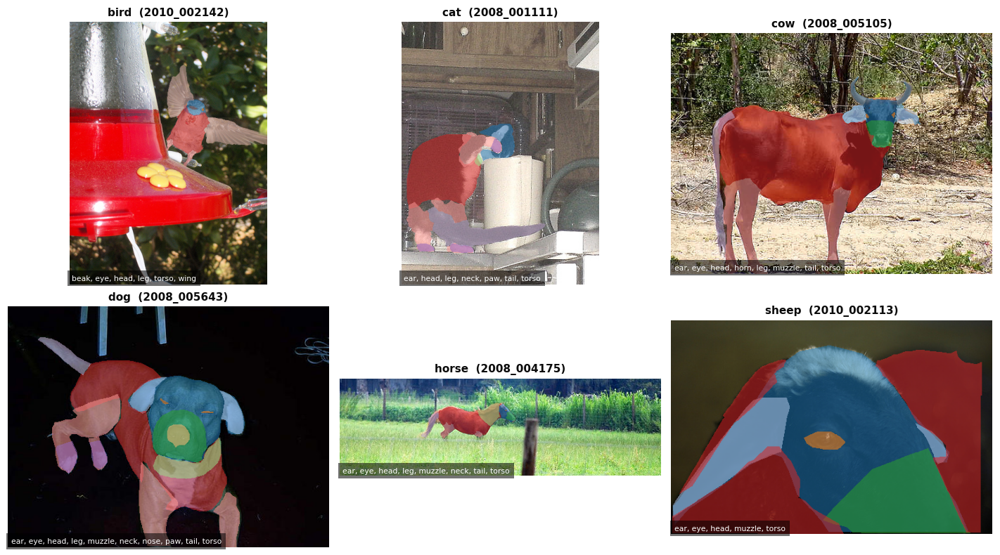

In [8]:
# one example per species with its merged part masks
rng = np.random.default_rng(3)
cmap = plt.get_cmap("tab20")
fig, axes = plt.subplots(2, 3, figsize=(13, 7.4))
val_ids = D.animal_ids(D.voc_split("val"))
for ax, sp in zip(axes.ravel(), SPECIES):
    cands = [i for i in val_ids[::7] if (o := D.load_anno(i)) and len(o) == 1 and o[0]["species"] == sp and len(o[0]["parts"]) >= 5]
    img_id = cands[int(rng.integers(len(cands)))]
    img = np.asarray(Image.open(D.image_path(img_id)).convert("RGB")).astype(float)
    o = D.load_anno(img_id)[0]
    for p, ms in o["parts"].items():
        c = np.array(cmap(PARTS.index(p))[:3]) * 255
        for m in ms:
            img[m] = 0.45 * img[m] + 0.55 * c
    ax.imshow(img.astype(np.uint8)); ax.axis("off")
    ax.set_title(f"{sp}  ({img_id})")
    ax.text(0.01, 0.01, ", ".join(sorted(o["parts"])), transform=ax.transAxes, fontsize=7, color="white",
            va="bottom", bbox=dict(facecolor="black", alpha=0.55, lw=0))
plt.tight_layout(); savefig(fig, "fig01_pascal_part_examples.png"); plt.show()

saved -> outputs\figures\fig02_dataset_counts.png


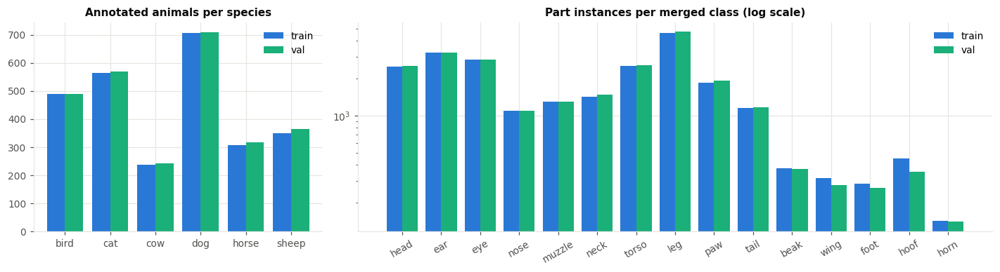

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
x = np.arange(len(SPECIES))
axes[0].bar(x - 0.2, [STATS["train"]["animals"][s] for s in SPECIES], 0.4, color=PALETTE[0], label="train")
axes[0].bar(x + 0.2, [STATS["val"]["animals"][s] for s in SPECIES], 0.4, color=PALETTE[2], label="val")
axes[0].set_xticks(x, SPECIES); axes[0].set_title("Annotated animals per species"); axes[0].legend()
x = np.arange(len(PARTS))
axes[1].bar(x - 0.2, [STATS["train"]["part_instances"][p] for p in PARTS], 0.4, color=PALETTE[0], label="train")
axes[1].bar(x + 0.2, [STATS["val"]["part_instances"][p] for p in PARTS], 0.4, color=PALETTE[2], label="val")
axes[1].set_xticks(x, PARTS, rotation=30); axes[1].set_yscale("log"); axes[1].legend()
axes[1].set_title("Part instances per merged class (log scale)")
plt.tight_layout(); savefig(fig, "fig02_dataset_counts.png"); plt.show()

## 1.4 The phone photographs (real-world test images)

Five photographs: three dogs and two cats. `4.jpg` and `5.jpg` carry an EXIF rotation tag, and `load_image` applies it.
`5.jpg` is a person holding a cat, which adds a distractor: a prompt about *ears* could be answered with the
person's ears. These images have no ground-truth masks, so on them the systems are judged by inspection (§7.6), while
IoU and Dice come from PASCAL-Part (§7.2).

saved -> outputs\figures\fig03_phone_images.png


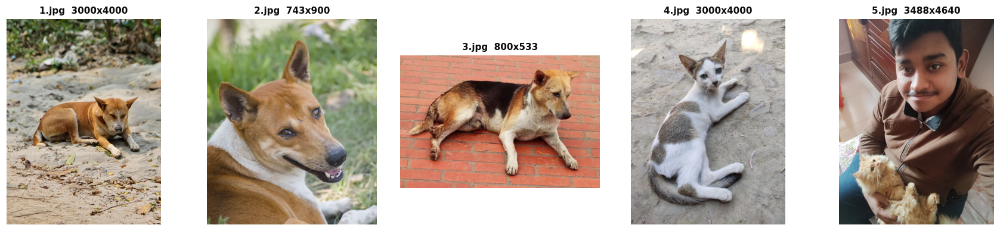

In [10]:
PHONE_IMGS = sorted(PHONE.glob("*.jpg"), key=lambda p: int(p.stem))
fig, axes = plt.subplots(1, len(PHONE_IMGS), figsize=(16, 3.6))
for ax, p in zip(axes, PHONE_IMGS):
    im = load_image(p)
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{p.name}  {im.width}x{im.height}")
plt.tight_layout(); savefig(fig, "fig03_phone_images.png"); plt.show()

---
# 2. Prompts used for testing

Both systems receive exactly the same prompts. Four styles test different levels of language understanding:

* **direct**: names the part plainly (*"Show the ears of this cat."*);
* **synonym**: uses another word for the part or the animal (*"Segment the puppy's snout."*);
* **indirect**: describes the part by what it does, without naming it (*"Show me the part this dog uses to smell."*);
* **impossible**: asks for a part the animal does not have (*"Show the wings of this dog."*). The correct answer is to
  say so and segment nothing.

In [11]:
%%writefile bp_eval.py
"""Test prompts, a resumable evaluation runner, and the Part C metrics."""
import json, random, re, time
from pathlib import Path
import numpy as np
from bp_common import PARTS, SPECIES_PARTS, PLURAL, iou_dice, colour_names

# --------------------------------------------------------------------------------------------- prompts
SPECIES_SYN = {"cat": ["kitten", "kitty"], "dog": ["puppy", "pooch"], "bird": ["birdie"], "horse": ["pony"],
               "cow": ["calf", "cattle animal"], "sheep": ["lamb"]}
PART_SYN = {"head": ["face"], "nose": ["nostrils"], "muzzle": ["snout", "mouth area"], "neck": ["throat"],
            "torso": ["body", "belly"], "leg": ["limbs"], "paw": ["feet"], "beak": ["bill"],
            "foot": ["feet", "talons"], "hoof": ["feet"], "horn": ["horns"], "ear": ["ear flaps"],
            "eye": ["eyeballs"], "tail": ["tail"], "wing": ["wings"]}
INDIRECT = {
    "head": "the part of this {s} that contains its brain and face",
    "ear": "the part this {s} uses to hear",
    "eye": "the part this {s} sees with",
    "nose": "the part this {s} uses to smell",
    "muzzle": "the front part of this {s}'s face where its mouth and jaws are",
    "neck": "the part that joins this {s}'s head to its body",
    "torso": "the main trunk of this {s}'s body",
    "leg": "the limbs this {s} stands and runs on",
    "paw": "the soft padded parts this {s} walks on",
    "tail": "the part at the back end that this {s} wags or swishes",
    "beak": "the part this {s} pecks with",
    "wing": "the parts this {s} flies with",
    "foot": "the parts this {s} perches with",
    "hoof": "the hard tips of this {s}'s legs",
    "horn": "the hard pointed growths on this {s}'s head",
}
DIRECT = ["Show the {p} of this {s}.", "Identify the {p} of this {s}.", "Segment the {s}'s {p}.",
          "Can you highlight the {p} of the {s}?"]
IMPOSSIBLE = {"cat": ["wing", "beak", "hoof", "horn"], "dog": ["wing", "beak", "hoof", "horn"],
              "bird": ["horn", "hoof", "paw"], "horse": ["wing", "beak", "horn", "paw"],
              "cow": ["wing", "beak", "paw"], "sheep": ["wing", "beak", "paw"]}


def make_prompt(species, part, style, rng):
    if style == "direct":
        return rng.choice(DIRECT).format(p=PLURAL[part], s=species)
    if style == "synonym":
        return rng.choice(DIRECT).format(p=rng.choice(PART_SYN[part]), s=rng.choice(SPECIES_SYN[species]))
    if style == "indirect":
        return "Show me " + INDIRECT[part].format(s=species) + "."
    raise ValueError(style)


def build_prompts(test_items, load_anno, n_pos=3, neg_every=3, min_px=80, seed=0):
    """test_items: [(img_id, species)]. Every image gets up to n_pos prompts for annotated parts, cycling the
    three styles; every neg_every-th image also gets one impossible prompt."""
    rng = random.Random(seed)
    styles = ["direct", "synonym", "indirect"]
    rows, k = [], 0
    part_count = {p: 0 for p in PARTS}
    for j, (img_id, sp) in enumerate(test_items):
        o = load_anno(img_id)[0]
        avail = [p for p, ms in o["parts"].items() if sum(m.sum() for m in ms) >= min_px]
        avail.sort(key=lambda p: (part_count[p], rng.random()))          # balance parts over the test set
        for p in avail[:n_pos]:
            part_count[p] += 1
            st = styles[k % 3]
            k += 1
            rows.append({"img_id": img_id, "species": sp, "part": p, "style": st, "negative": False,
                         "prompt": make_prompt(sp, p, st, rng)})
        if j % neg_every == 0:
            p = rng.choice(IMPOSSIBLE[sp])
            rows.append({"img_id": img_id, "species": sp, "part": p, "style": "impossible", "negative": True,
                         "prompt": rng.choice(DIRECT).format(p=PLURAL[p], s=sp)})
    for i, r in enumerate(rows):
        r["qid"] = i
    return rows


# --------------------------------------------------------------------------------------------- runner
def run_resumable(system, rows, image_fn, out_jsonl, describe_qids=(), extra=None, log_every=25):
    """Run system(image, prompt) for every row; append one JSON line per prompt so a killed run resumes."""
    out_jsonl = Path(out_jsonl)
    done = {}
    if out_jsonl.exists():
        for l in out_jsonl.read_text().splitlines():
            d = json.loads(l)
            done[d["qid"]] = d
    masks_dir = out_jsonl.with_suffix("")
    masks_dir.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    with open(out_jsonl, "a") as f:
        for n, r in enumerate(rows):
            if r["qid"] in done:
                continue
            res = system(image_fn(r["img_id"]), r["prompt"], describe=r["qid"] in describe_qids)
            res["_qid"] = r["qid"]
            np.save(masks_dir / f"{r['qid']}.npy", np.packbits(res["mask"]))
            rec = {"qid": r["qid"], "status": res["status"], "parse": {k: v for k, v in res.get("parse", {}).items() if k != "raw"},
                   "species_pred": res.get("species"), "parts_pred": res.get("parts"), "boxes": res.get("boxes"),
                   "description": res.get("description"), "time": res.get("time"), "shape": list(res["mask"].shape)}
            if extra:
                rec.update(extra(res))
            f.write(json.dumps(rec, default=float) + "\n")
            f.flush()
            done[r["qid"]] = rec
            if log_every and len(done) % log_every == 0:
                print(f"  {len(done)}/{len(rows)}  ({time.time() - t0:.0f}s)", flush=True)
    return [done[r["qid"]] for r in rows]


def load_mask(out_jsonl, qid, shape):
    bits = np.load(Path(out_jsonl).with_suffix("") / f"{qid}.npy")
    return np.unpackbits(bits)[: shape[0] * shape[1]].reshape(shape).astype(bool)


# --------------------------------------------------------------------------------------------- metrics
def gt_part_mask(obj, part, shape):
    ms = obj["parts"].get(part, [])
    m = np.zeros(obj["mask"].shape, bool)
    for x in ms:
        m |= x
    return _resize_mask(m, shape)


def _resize_mask(m, shape):
    if m.shape == tuple(shape):
        return m
    import cv2
    return cv2.resize(m.astype(np.uint8), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST) > 0


def correct_part(pred, obj, part):
    """Which annotated part does the predicted mask match best? PASCAL-Part masks are nested (the head contains the
    ears, eyes and nose; the leg contains the paw; the torso the neck), so a pixel vote would always favour the larger
    part. The match is therefore the part with the highest IoU, which normalises by part size."""
    if not pred.any():
        return False, None
    ious = {p: iou_dice(pred, _resize_mask(np.any(ms, 0), pred.shape))[0] for p, ms in obj["parts"].items()}
    best = max(ious, key=ious.get)
    return (ious[best] > 0 and best == part), (best if ious[best] > 0 else None)


COLOUR_FAMILY = {
    "black": ["black", "dark grey", "dark", "charcoal"],
    "white": ["white", "cream", "light grey", "pale", "ivory"],
    "grey": ["grey", "gray", "dark grey", "light grey", "silver"],
    "brown": ["brown", "light brown", "dark brown", "reddish brown", "tan", "beige", "chestnut", "chocolate", "fawn"],
    "orange": ["ginger", "orange", "golden", "tan", "tawny", "rust", "caramel", "reddish brown"],
    "yellow": ["yellow", "golden", "cream", "blonde"],
    "pink": ["pink", "rosy"],
    "red": ["red", "reddish"],
}
_FAM_OF = {}
for fam, names in COLOUR_FAMILY.items():
    for n in names:
        _FAM_OF.setdefault(n, set()).add(fam)
COLOUR_WORDS = sorted({n for ns in COLOUR_FAMILY.values() for n in ns} | {"gray"}, key=len, reverse=True)
FUNCTION_RE = re.compile(r"\b(used (for|to)|helps?|help(ing)? (it|the|them)|allows?|enables?|function|serves?|"
                         r"important for|responsible for|for (hearing|seeing|vision|smell|balance|walking|flying)|"
                         r"protects?|support)", re.I)
SPECIES_TERMS = {"cat": ["cat", "kitten", "kitty", "feline"], "dog": ["dog", "puppy", "canine", "pooch"],
                 "bird": ["bird"], "horse": ["horse", "pony", "equine"], "cow": ["cow", "cattle", "calf", "bovine"],
                 "sheep": ["sheep", "lamb", "ewe"]}
PART_TERMS = {"head": ["head", "face"], "ear": ["ear"], "eye": ["eye"], "nose": ["nose", "nostril"],
              "muzzle": ["muzzle", "snout", "mouth", "jaw"], "neck": ["neck"], "torso": ["torso", "body", "belly", "chest", "back"],
              "leg": ["leg", "limb"], "paw": ["paw", "feet", "foot", "pad"], "tail": ["tail"], "beak": ["beak", "bill"],
              "wing": ["wing"], "foot": ["feet", "foot", "talon", "claw"], "hoof": ["hoof", "hooves"], "horn": ["horn"]}


def colours_in(text):
    t = text.lower()
    found = []
    for w in COLOUR_WORDS:
        if re.search(rf"\b{w}\b", t):
            found.append(w)
            t = re.sub(rf"\b{w}\b", " ", t)
    return found


def description_scores(text, species, part, img_rgb, gt_mask):
    t = (text or "").lower()
    words = re.findall(r"[a-z']+", t)
    ref = {f for n, _ in colour_names(img_rgb, gt_mask, k=3, min_share=0.15) for f in _FAM_OF.get(n, {n})}
    said = colours_in(t)
    said_f = {f for w in said for f in _FAM_OF.get(w, {w})}
    other = [s for s in SPECIES_TERMS if s != species and any(re.search(rf"\b{w}s?\b", t) for w in SPECIES_TERMS[s])]
    return {
        "mentions_part": any(w in t for w in PART_TERMS[part]),
        "mentions_species": any(re.search(rf"\b{w}", t) for w in SPECIES_TERMS[species]),
        "states_function": bool(FUNCTION_RE.search(t)),
        "colour_correct": bool(said_f & ref) if said_f else False,
        "concise": 15 <= len(words) <= 90,
        "wrong_species": bool(other),
        "n_words": len(words),
    }

Overwriting bp_eval.py


In [12]:
import bp_eval as E

# PASCAL-Part test set: held-out VOC *val* images that contain exactly one animal
TEST_PER_SPECIES = {"cat": 40, "dog": 40, "bird": 10, "horse": 10, "cow": 10, "sheep": 10}
test_file = RES / "test_prompts.csv"
if test_file.exists():
    TEST = pd.read_csv(test_file).to_dict("records")
else:
    items, pool = D.select_test_images(D.animal_ids(D.voc_split("val")), TEST_PER_SPECIES, seed=SEED)
    print("eligible single-animal val images:", pool)
    TEST = E.build_prompts(items, D.load_anno, n_pos=3, neg_every=3, seed=SEED)
    pd.DataFrame(TEST).to_csv(test_file, index=False)
TEST_DF = pd.DataFrame(TEST)
print(f"{TEST_DF.img_id.nunique()} test images, {len(TEST_DF)} prompts")
display(pd.crosstab(TEST_DF.species, TEST_DF["style"], margins=True))
display(TEST_DF.groupby("style").head(2)[["img_id", "species", "part", "style", "prompt"]])

120 test images, 400 prompts


style,direct,impossible,indirect,synonym,All
species,,,,,
bird,10,3,10,10,33
cat,40,14,40,40,134
cow,10,3,10,10,33
dog,40,13,40,40,133
horse,10,4,10,10,34
sheep,10,3,10,10,33
All,120,40,120,120,400


,img_id,species,part,style,prompt
0,2008_000222,cat,nose,direct,Can you highlight the nose of the cat?
1,2008_000222,cat,paw,synonym,Segment the kitten's feet.
2,2008_000222,cat,neck,indirect,Show me the part that joins this cat's head to...
3,2008_000222,cat,hoof,impossible,Identify the hooves of this cat.
4,2008_001374,cat,eye,direct,Show the eyes of this cat.
5,2008_001374,cat,tail,synonym,Segment the kitten's tail.
6,2008_001374,cat,ear,indirect,Show me the part this cat uses to hear.
13,2008_002845,cat,hoof,impossible,Can you highlight the hooves of the cat?


In [13]:
# prompts for the phone photographs (same for both systems)
PHONE_PROMPTS = [
    ("1.jpg", "dog", "Show the ears of this dog.", "ear", "direct"),
    ("1.jpg", "dog", "Where is the dog's tail?", "tail", "direct"),
    ("1.jpg", "dog", "Segment the puppy's snout.", "muzzle", "synonym"),
    ("1.jpg", "dog", "Show me the part this dog uses to smell.", "nose", "indirect"),
    ("1.jpg", "dog", "Show the wings of this dog.", "wing", "impossible"),
    ("2.jpg", "dog", "Identify the ears of this dog.", "ear", "direct"),
    ("2.jpg", "dog", "Show the eyes of the pooch.", "eye", "synonym"),
    ("2.jpg", "dog", "Segment the dog's nose.", "nose", "direct"),
    ("2.jpg", "dog", "Show me the part this dog sees with.", "eye", "indirect"),
    ("2.jpg", "dog", "Show the horns of this dog.", "horn", "impossible"),
    ("3.jpg", "dog", "Show the legs of this dog.", "leg", "direct"),
    ("3.jpg", "dog", "Show me the part at the back end that this dog wags.", "tail", "indirect"),
    ("3.jpg", "dog", "Segment the dog's head.", "head", "direct"),
    ("3.jpg", "dog", "Highlight the puppy's feet.", "paw", "synonym"),
    ("3.jpg", "dog", "Show the beak of this dog.", "beak", "impossible"),
    ("4.jpg", "cat", "Identify the ears of this cat.", "ear", "direct"),
    ("4.jpg", "cat", "Show the kitten's eyes.", "eye", "synonym"),
    ("4.jpg", "cat", "Segment the cat's tail.", "tail", "direct"),
    ("4.jpg", "cat", "Show me the limbs this cat stands and runs on.", "leg", "indirect"),
    ("4.jpg", "cat", "Show the wings of this cat.", "wing", "impossible"),
    ("5.jpg", "cat", "Show the ears of this cat.", "ear", "direct"),
    ("5.jpg", "cat", "Segment the cat's eyes.", "eye", "direct"),
    ("5.jpg", "cat", "Show the head of the kitty.", "head", "synonym"),
    ("5.jpg", "cat", "Show me the soft padded parts this cat walks on.", "paw", "indirect"),
    ("5.jpg", "cat", "Show the hooves of this cat.", "hoof", "impossible"),
]
PHONE_DF = pd.DataFrame(PHONE_PROMPTS, columns=["image", "species", "prompt", "part", "style"])
PHONE_DF["qid"] = range(len(PHONE_DF)); PHONE_DF["negative"] = PHONE_DF["style"] == "impossible"
PHONE_DF.to_csv(RES / "phone_prompts.csv", index=False)
print(len(PHONE_DF), "phone prompts"); display(PHONE_DF.style.hide(axis="index"))

25 phone prompts


image,species,prompt,part,style,qid,negative
1.jpg,dog,Show the ears of this dog.,ear,direct,0,False
1.jpg,dog,Where is the dog's tail?,tail,direct,1,False
1.jpg,dog,Segment the puppy's snout.,muzzle,synonym,2,False
1.jpg,dog,Show me the part this dog uses to smell.,nose,indirect,3,False
1.jpg,dog,Show the wings of this dog.,wing,impossible,4,True
2.jpg,dog,Identify the ears of this dog.,ear,direct,5,False
2.jpg,dog,Show the eyes of the pooch.,eye,synonym,6,False
2.jpg,dog,Segment the dog's nose.,nose,direct,7,False
2.jpg,dog,Show me the part this dog sees with.,eye,indirect,8,False
2.jpg,dog,Show the horns of this dog.,horn,impossible,9,True


---
# 3. Part A — System without a vision-language model

**Pipeline.** `prompt → parser → (species, part)`; `image → YOLO11m (COCO) → animal box → padded crop → YOLO11s-seg
fine-tuned on PASCAL-Part → part boxes → SAM 2 → part mask`; `description = predefined text for (species, part) +
colour, count and size measured on the mask`.

* **Prompt understanding without a VLM.** A keyword lexicon (synonyms, plurals, small typos, species words) maps the
  prompt to a part. Only when no keyword is found does a *text-only* sentence-embedding model (MiniLM) compare the
  prompt with dictionary definitions of the parts. This counts as a language model that does not use visual input, which the
  assignment allows. An ontology (`SPECIES_PARTS`) rejects impossible requests such as wings on a cat.
* **Why a fine-tuned part detector?** COCO-trained YOLO only knows whole animals (cat, dog, bird, …); it has no
  *ear* or *tail* class. The part detector is therefore fine-tuned on PASCAL-Part. It is trained on **padded animal crops**,
  because at test time it runs on the crop around the animal found by the COCO detector, which makes small parts larger.
* **Why SAM 2 after YOLO-seg?** YOLO-seg already outputs masks, but its masks are low resolution. SAM 2 turns each part
  box into a sharper mask. §7.2 measures whether SAM 2 actually helps.

In [14]:
%%writefile system_a.py
"""System A -- prompt-guided body-part segmentation WITHOUT a vision-language model.

prompt --(keyword lexicon + text-only sentence embedding)--> (species, part)
image  --YOLO11 (COCO)--> animal box --YOLO11-seg fine-tuned on PASCAL-Part--> part boxes --SAM 2--> mask
description = predefined text for (species, part) + colour / count / size measured from the mask
"""
import re, difflib
import numpy as np
import torch
from bp_common import (PARTS, SPECIES, SPECIES_PARTS, PLURAL, WEIGHTS, SAM2Segmenter, colour_names,
                       load_image, limit_size, Timer)

# --------------------------------------------------------------------------------------------- lexicon
SPECIES_WORDS = {
    "cat": ["cat", "kitten", "kitty", "feline", "kitties", "tomcat"],
    "dog": ["dog", "puppy", "pup", "doggy", "doggo", "canine", "hound", "pooch"],
    "bird": ["bird", "birdie", "chick", "parrot", "pigeon", "sparrow", "duck", "hen", "eagle", "seagull"],
    "horse": ["horse", "pony", "foal", "mare", "stallion", "colt"],
    "cow": ["cow", "cattle", "calf", "bull", "ox", "oxen"],
    "sheep": ["sheep", "lamb", "ram", "ewe"],
}
# noun synonyms -> canonical part. "@feet" etc. are resolved per species below.
PART_WORDS = {
    "head": ["head", "face", "skull"],
    "ear": ["ear", "earflap", "pinna"],
    "eye": ["eye", "eyeball"],
    "nose": ["nose", "nostril"],
    "muzzle": ["muzzle", "snout", "mouth", "jaw", "lip"],
    "neck": ["neck", "throat", "nape"],
    "torso": ["torso", "body", "belly", "trunk", "chest", "abdomen", "stomach", "back", "flank"],
    "leg": ["leg", "limb", "thigh"],
    "paw": ["paw", "pad"],
    "@feet": ["foot", "feet", "toe"],
    "tail": ["tail"],
    "beak": ["beak", "bill"],
    "wing": ["wing", "feather"],
    "foot": ["talon", "claw"],
    "hoof": ["hoof", "hooves"],
    "horn": ["horn", "antler"],
}
# dictionary-style definitions, used only when no keyword matches (text-only semantic fallback)
PART_GLOSS = {
    "head": "the head, the top front part of the body containing the brain, face, eyes and mouth",
    "ear": "the ear, the organ used for hearing and listening to sounds",
    "eye": "the eye, the organ used for seeing and vision",
    "nose": "the nose, the organ used for smelling and sniffing and breathing",
    "muzzle": "the muzzle or snout, the projecting front part of the face with the mouth and jaws",
    "neck": "the neck, the part connecting the head to the body",
    "torso": "the torso, the main central trunk of the body, the chest, back and belly",
    "leg": "the legs, the limbs used for standing, walking and running",
    "paw": "the paws, the soft padded feet at the ends of the legs used for walking",
    "tail": "the tail, the flexible appendage at the rear end that wags, swishes or balances",
    "beak": "the beak, the hard pointed mouth of a bird used for pecking and eating",
    "wing": "the wings, the feathered limbs a bird uses for flying",
    "foot": "the bird's feet, used for perching and gripping",
    "hoof": "the hooves, the hard horny tips of the legs",
    "horn": "the horns, the hard pointed growths on the head",
}


def _norm(word):
    w = word.lower()
    for a, b in (("hooves", "hoof"), ("feet", "feet"), ("teeth", "tooth"), ("calves", "calf"),
                 ("puppies", "puppy"), ("kitties", "kitty"), ("oxen", "ox")):
        if w == a:
            return b
    if len(w) > 3 and w.endswith("es") and w[:-2] in _ALL_WORDS:
        return w[:-2]
    if len(w) > 3 and w.endswith("s") and not w.endswith("ss"):
        return w[:-1]
    return w


_ALL_WORDS = {w for ws in list(SPECIES_WORDS.values()) + list(PART_WORDS.values()) for w in ws}


def resolve_part(key, species):
    """Map a lexicon key to a part that exists for this species (e.g. 'feet' -> paw / foot / hoof)."""
    avail = SPECIES_PARTS.get(species, PARTS)
    if key == "@feet":
        for p in ("paw", "foot", "hoof", "leg"):
            if p in avail:
                return p
    if key == "nose" and "nose" not in avail and "muzzle" in avail:
        return "muzzle"
    if key == "muzzle" and "muzzle" not in avail and "nose" in avail:
        return "nose"
    if key == "foot" and "foot" not in avail:
        return resolve_part("@feet", species)
    return key


class PromptParser:
    """Rule-based parser with a text-only sentence-embedding fallback (no image input)."""

    def __init__(self, use_embeddings=True, sim_threshold=0.35):
        self.sim_threshold = sim_threshold
        self.emb = None
        if use_embeddings:
            from sentence_transformers import SentenceTransformer
            self.emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
            self.gloss_keys = list(PART_GLOSS)
            self.gloss_vec = self.emb.encode([PART_GLOSS[k] for k in self.gloss_keys], normalize_embeddings=True)

    def __call__(self, prompt):
        toks = [_norm(t) for t in re.findall(r"[a-zA-Z]+", prompt)]
        species, keys = None, []
        vocab = {w: ("S", s) for s, ws in SPECIES_WORDS.items() for w in ws}
        vocab.update({w: ("P", p) for p, ws in PART_WORDS.items() for w in ws})
        for t in toks:
            hit = vocab.get(t)
            if hit is None and len(t) >= 4:                      # tolerate small typos ("tial", "eares")
                close = difflib.get_close_matches(t, vocab.keys(), n=1, cutoff=0.85)
                hit = vocab[close[0]] if close else None
            if hit is None:
                continue
            kind, val = hit
            if kind == "S" and species is None:
                species = val
            elif kind == "P" and val not in keys:
                keys.append(val)
        method = "keyword"
        if not keys and self.emb is not None:                   # e.g. "the part it hears with"
            v = self.emb.encode([prompt], normalize_embeddings=True)[0]
            sims = self.gloss_vec @ v
            j = int(np.argmax(sims))
            if sims[j] >= self.sim_threshold:
                keys, method = [self.gloss_keys[j]], f"embedding (cos={sims[j]:.2f})"
        if not keys:
            return {"species": species, "keys": [], "method": "none", "ok": False}
        return {"species": species, "keys": keys, "method": method, "ok": True}


# --------------------------------------------------------------------------------------------- descriptions
APPEARANCE = {
    "head": "a rounded head that carries the face, eyes, ears and mouth",
    "ear": "ears that are thin flaps of skin and cartilage covered in short fur",
    "eye": "forward-facing eyes with a dark pupil inside a coloured iris",
    "nose": "a small, moist, hairless nose leather with two nostrils",
    "muzzle": "an elongated muzzle that holds the jaws, teeth and nose",
    "neck": "a muscular neck that joins the head to the body",
    "torso": "a torso that forms the main bulk of the body, covered by the coat",
    "leg": "slender, muscular legs",
    "paw": "paws with soft pads on the underside and short claws",
    "tail": "a flexible, fur-covered tail",
    "beak": "a hard, keratin-covered beak",
    "wing": "feathered wings folded along the sides of the body",
    "foot": "scaly feet with clawed toes",
    "hoof": "hard keratin hooves at the tips of the legs",
    "horn": "curved horns made of bone covered by keratin",
}
FUNCTION = {
    "head": "It houses the brain and the main sense organs, so it is the centre of perception and feeding.",
    "ear": "Ears collect sound and turn towards it; they also help with balance and show the animal's mood.",
    "eye": "Eyes provide vision, including good motion detection and sight in dim light.",
    "nose": "The nose is used for breathing and for a very sensitive sense of smell.",
    "muzzle": "The muzzle holds the teeth for biting and chewing and the nose for smelling.",
    "neck": "The neck supports and moves the head and protects the airway, food pipe and major blood vessels.",
    "torso": "The torso protects the vital organs such as the heart, lungs and stomach.",
    "leg": "Legs support the body's weight and allow walking, running and jumping.",
    "paw": "Paws cushion each step, give grip and silent movement, and help with grooming and handling objects.",
    "tail": "The tail helps with balance and is used for communication, such as signalling mood.",
    "beak": "The beak is used for feeding, preening feathers, building nests and defence.",
    "wing": "Wings generate lift for flight and are also used for display and balance.",
    "foot": "Feet are used for perching, walking and gripping food or branches.",
    "hoof": "Hooves bear the animal's weight and protect the toes on hard ground.",
    "horn": "Horns are used for defence, fighting rivals and display.",
}
SPECIES_APPEARANCE = {
    ("cat", "ear"): "triangular, upright ears that can rotate independently",
    ("dog", "ear"): "ears that may be erect or floppy depending on the breed",
    ("cat", "eye"): "large eyes with vertical slit pupils",
    ("dog", "eye"): "round eyes with a dark iris",
    ("cat", "nose"): "a small triangular pink or dark nose",
    ("dog", "nose"): "a wet, dark nose with large nostrils",
    ("cat", "tail"): "a long, slender and flexible tail",
    ("dog", "tail"): "a tail whose shape varies from straight to curled",
    ("cat", "paw"): "small rounded paws with retractable claws",
    ("dog", "paw"): "paws with thick pads and non-retractable claws",
    ("horse", "muzzle"): "a soft muzzle with large nostrils and sensitive whiskers",
}
SPECIES_FUNCTION = {
    ("dog", "tail"): "Dogs wag the tail to communicate excitement, friendliness or nervousness, and use it for balance.",
    ("cat", "tail"): "Cats use the tail for balance when jumping and climbing and to signal their mood.",
    ("dog", "nose"): "A dog's nose is extremely sensitive, with hundreds of millions of scent receptors.",
    ("cat", "ear"): "Cat ears hear very high-pitched sounds, which helps in hunting small prey.",
    ("cat", "eye"): "Cat eyes see well in very low light, which suits hunting at dawn and dusk.",
}


def describe_a(species, part, img_rgb, mask, n_inst, animal_area):
    sp = species or "animal"
    app = SPECIES_APPEARANCE.get((sp, part), APPEARANCE[part])
    fun = SPECIES_FUNCTION.get((sp, part), FUNCTION[part])
    cols = [c for c, _ in colour_names(img_rgb, mask)][:2]
    col_txt = " and ".join(cols) if cols else "of unclear colour"
    share = 100 * mask.sum() / max(animal_area, 1)
    n_txt = f"{n_inst} {part} region{'s' if n_inst > 1 else ''}"
    return (f"The {sp}'s {PLURAL[part]}: a {sp} typically has {app}. "
            f"In this image the system found {n_txt}, mainly {col_txt}, covering about {share:.1f}% of the "
            f"{sp}'s detected area. Function: {fun}")


# --------------------------------------------------------------------------------------------- system
COCO_ANIMALS = {14: "bird", 15: "cat", 16: "dog", 17: "horse", 18: "sheep", 19: "cow"}


class SystemA:
    name = "System A (YOLO + SAM 2, no VLM)"

    def __init__(self, part_weights=None, det_weights="yolo11m.pt", device="cuda", use_sam=True,
                 sam=None, parser=None, part_conf=0.25, imgsz=512):
        from ultralytics import YOLO
        part_weights = part_weights or (WEIGHTS / "parts_yolo11s_seg.pt")
        det = WEIGHTS / det_weights
        self.det = YOLO(str(det) if det.exists() else det_weights)
        self.parts = YOLO(str(part_weights))
        self.sam = sam if sam is not None else (SAM2Segmenter(device=device) if use_sam else None)
        self.use_sam = use_sam
        self.parser = parser or PromptParser()
        self.device, self.part_conf, self.imgsz = device, part_conf, imgsz

    def detect_animal(self, img_rgb, species):
        r = self.det(img_rgb[:, :, ::-1], conf=0.25, classes=list(COCO_ANIMALS), verbose=False, device=self.device)[0]
        dets = [(COCO_ANIMALS[int(c)], float(s), b.tolist())
                for b, s, c in zip(r.boxes.xyxy.cpu(), r.boxes.conf.cpu(), r.boxes.cls.cpu())]
        if not dets:
            return None
        same = [d for d in dets if d[0] == species]
        pool = same if same else dets
        return max(pool, key=lambda d: d[1] * (1 + 1e-6 * (d[2][2] - d[2][0]) * (d[2][3] - d[2][1])))

    def __call__(self, image, prompt, describe=True):
        tm = Timer()
        pil, _ = limit_size(load_image(image))
        img = np.asarray(pil)
        H, W = img.shape[:2]
        out = {"system": "A", "prompt": prompt, "mask": np.zeros((H, W), bool), "boxes": [], "image": img,
               "status": "ok"}
        with tm("parse"):
            q = self.parser(prompt)
        out["parse"] = q
        with tm("detect_animal"):
            det = self.detect_animal(img, q["species"])
        # the user's word for the animal wins; the detector supplies the location (and the species if none is given)
        species = q["species"] or (det[0] if det else None)
        if q["species"] and det and det[0] != q["species"]:
            out["note"] = f"prompt says {q['species']} but the detector labelled the animal a {det[0]}"
        abox = det[2] if det else [0, 0, W, H]
        out.update(species=species, animal_box=abox)
        if not q["ok"]:
            out.update(status="not_understood", description="Sorry, the requested body part could not be recognised in the prompt.")
            out["time"] = tm.t
            return out
        parts = [resolve_part(k, species) for k in q["keys"]]
        out["parts"] = parts
        valid = [p for p in parts if species is None or p in SPECIES_PARTS.get(species, PARTS)]
        if not valid:
            out.update(status="impossible",
                       description=f"A {species} does not have {PLURAL[parts[0]]}, so nothing was segmented.")
            out["time"] = tm.t
            return out
        # ---- part detection on a padded crop around the animal
        x1, y1, x2, y2 = abox
        pw, ph = 0.15 * (x2 - x1), 0.15 * (y2 - y1)
        cx1, cy1, cx2, cy2 = int(max(0, x1 - pw)), int(max(0, y1 - ph)), int(min(W, x2 + pw)), int(min(H, y2 + ph))
        crop = np.ascontiguousarray(img[cy1:cy2, cx1:cx2])
        with tm("detect_parts"):
            r = self.parts(crop[:, :, ::-1], conf=self.part_conf, imgsz=self.imgsz, verbose=False, device=self.device)[0]
        want = {PARTS.index(p) for p in valid}
        boxes, scores, polys, kept_cls = [], [], [], []
        for i, (b, s, c) in enumerate(zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy())):
            if int(c) in want:
                boxes.append((b + [cx1, cy1, cx1, cy1]).tolist())
                scores.append(float(s))
                kept_cls.append(PARTS[int(c)])
                polys.append(r.masks.xy[i] + [cx1, cy1] if r.masks is not None else None)
        out.update(boxes=boxes, scores=scores)
        if not boxes:
            out.update(status="not_found",
                       description=f"No {PLURAL[valid[0]]} could be found on the {species or 'animal'} in this image.")
            out["time"] = tm.t
            return out
        # ---- segmentation: SAM 2 from the part boxes (or the YOLO-seg masks for the ablation)
        with tm("segment"):
            if self.use_sam:
                mask, inst = self.sam(img, boxes)
            else:
                import cv2
                mask = np.zeros((H, W), np.uint8)
                for p in polys:
                    if p is not None and len(p) >= 3:
                        cv2.fillPoly(mask, [p.astype(np.int32)], 1)
                mask, inst = mask.astype(bool), boxes
        out["mask"] = mask
        if describe:
            with tm("describe"):
                aarea = (abox[2] - abox[0]) * (abox[3] - abox[1])
                out["description"] = " ".join(describe_a(species, p, img, mask, kept_cls.count(p), aarea)
                                              for p in valid if p in kept_cls)
        out["time"] = tm.t
        return out

Overwriting system_a.py


## 3.1 Training the part detector

One training image per annotated animal: the animal's box padded by 15%, with every part polygon inside it. The VOC
*train* split is divided 90/10 into training and validation images (for model selection). The VOC *val* split is never
used for training, because it is the Part C test set.

In [15]:
YOLO_DIR = DATA / "yolo_parts"
if not (YOLO_DIR / "parts.yaml").exists():
    tr = [i for i in D.animal_ids(D.voc_split("train")) if D.load_anno(i)]
    random.Random(SEED).shuffle(tr)
    nval = len(tr) // 10
    n_tr = D.build_yolo_crops(sorted(tr[nval:]), YOLO_DIR, "train")
    n_va = D.build_yolo_crops(sorted(tr[:nval]), YOLO_DIR, "val")
    D.write_yaml(YOLO_DIR)
print("training crops:", len(list((YOLO_DIR / "images" / "train").glob("*.jpg"))),
      "| validation crops:", len(list((YOLO_DIR / "images" / "val").glob("*.jpg"))))

training crops: 2069 | validation crops: 225


In [16]:
%%writefile train_parts.py
"""Fine-tune YOLO11s-seg on PASCAL-Part animal-part crops (System A's part detector).
Run as a script (not inside the notebook) so data-loader workers work on Windows; resumes if interrupted."""
import sys, shutil
from pathlib import Path
from ultralytics import YOLO

ROOT = Path(__file__).resolve().parent
DATA_YAML = ROOT / "data" / "yolo_parts" / "parts.yaml"
RUN = ROOT / "outputs" / "runs" / "parts_yolo11s_seg"
EPOCHS = int(sys.argv[1]) if len(sys.argv) > 1 else 60

if __name__ == "__main__":
    last = RUN / "weights" / "last.pt"
    if last.exists():
        try:
            YOLO(str(last)).train(resume=True)          # continues an interrupted run
        except AssertionError as e:                     # "training to N epochs is finished"
            print("already finished:", e)
    else:
        w = ROOT / "weights" / "yolo11s-seg.pt"
        YOLO(str(w) if w.exists() else "yolo11s-seg.pt").train(
            data=str(DATA_YAML), epochs=EPOCHS, imgsz=512, batch=32, workers=6, seed=0,
            project=str(RUN.parent), name=RUN.name, exist_ok=True, patience=25,
            cos_lr=True, close_mosaic=10, degrees=10, plots=True, verbose=False)
    best = RUN / "weights" / "best.pt"
    if best.exists():
        shutil.copy(best, ROOT / "weights" / "parts_yolo11s_seg.pt")
        print("DONE ->", ROOT / "weights" / "parts_yolo11s_seg.pt")

Overwriting train_parts.py


part detector: D:\Study\MSc\2nd semester\Computer Vision\Assignments\13\weights\parts_yolo11s_seg.pt True


saved -> outputs\figures\fig04_part_detector_training.png


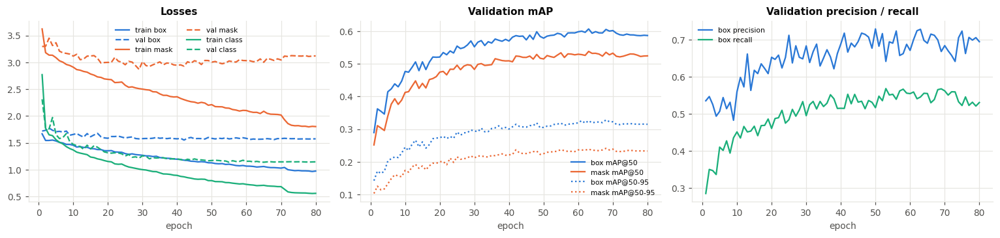

best epoch 63: box mAP@50 0.607, mask mAP@50 0.538


In [17]:
# training runs as a separate process (multi-worker data loading does not work inside a Windows notebook);
# it resumes automatically if it was interrupted, and is skipped if the trained weights already exist
PART_W = WEIGHTS / "parts_yolo11s_seg.pt"
if not PART_W.exists():
    r = subprocess.run([sys.executable, "train_parts.py", "80"], capture_output=True, text=True)
    print(r.stdout[-2000:], r.stderr[-2000:])
print("part detector:", PART_W, PART_W.exists())
hist = pd.read_csv(OUT / "runs" / "parts_yolo11s_seg" / "results.csv"); hist.columns = [c.strip() for c in hist.columns]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for k, lab, c in [("train/box_loss", "box", PALETTE[0]), ("train/seg_loss", "mask", PALETTE[1]), ("train/cls_loss", "class", PALETTE[2])]:
    axes[0].plot(hist.epoch, hist[k], color=c, label=f"train {lab}")
    axes[0].plot(hist.epoch, hist[k.replace("train", "val")], color=c, ls="--", label=f"val {lab}")
axes[0].set_title("Losses"); axes[0].legend(fontsize=7, ncol=2); axes[0].set_xlabel("epoch")
for k, lab, c in [("metrics/mAP50(B)", "box mAP@50", PALETTE[0]), ("metrics/mAP50(M)", "mask mAP@50", PALETTE[1]),
                  ("metrics/mAP50-95(B)", "box mAP@50-95", PALETTE[0]), ("metrics/mAP50-95(M)", "mask mAP@50-95", PALETTE[1])]:
    axes[1].plot(hist.epoch, hist[k], color=c, ls="-" if "50(" in k else ":", label=lab)
axes[1].set_title("Validation mAP"); axes[1].legend(fontsize=7); axes[1].set_xlabel("epoch")
axes[2].plot(hist.epoch, hist["metrics/precision(B)"], color=PALETTE[0], label="box precision")
axes[2].plot(hist.epoch, hist["metrics/recall(B)"], color=PALETTE[2], label="box recall")
axes[2].set_title("Validation precision / recall"); axes[2].legend(fontsize=7); axes[2].set_xlabel("epoch")
plt.tight_layout(); savefig(fig, "fig04_part_detector_training.png"); plt.show()
best = hist.loc[hist["metrics/mAP50(B)"].idxmax()]
print(f"best epoch {int(best.epoch)}: box mAP@50 {best['metrics/mAP50(B)']:.3f}, mask mAP@50 {best['metrics/mAP50(M)']:.3f}")

,box AP50,box AP50-95,mask AP50,mask AP50-95
head,0.874,0.664,0.806,0.361
ear,0.797,0.426,0.783,0.392
eye,0.623,0.267,0.583,0.225
nose,0.637,0.299,0.609,0.254
muzzle,0.893,0.488,0.869,0.463
neck,0.418,0.180,0.330,0.118
torso,0.842,0.557,0.663,0.335
leg,0.594,0.309,0.453,0.173
paw,0.600,0.268,0.549,0.230
tail,0.532,0.287,0.491,0.240


saved -> outputs\figures\fig05_part_detector_per_class.png


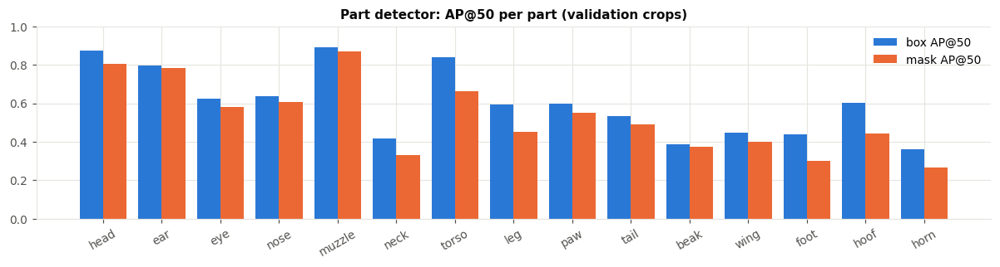

In [18]:
# per-class accuracy of the part detector on the validation crops
from ultralytics import YOLO
pc_file = RES / "part_detector_per_class.csv"
if pc_file.exists():
    PC = pd.read_csv(pc_file, index_col=0)
else:
    m = YOLO(str(PART_W))
    v = m.val(data=str(YOLO_DIR / "parts.yaml"), imgsz=512, batch=16, workers=0, verbose=False, plots=False)
    idx = list(v.box.ap_class_index)
    PC = pd.DataFrame({"box AP50": v.box.ap50, "box AP50-95": v.box.ap, "mask AP50": v.seg.ap50,
                       "mask AP50-95": v.seg.ap}, index=[PARTS[i] for i in idx]).round(3)
    PC.loc["mean"] = PC.mean().round(3)
    PC.to_csv(pc_file)
display(PC)
fig, ax = plt.subplots(figsize=(11, 3))
pp = PC.drop("mean")
x = np.arange(len(pp))
ax.bar(x - 0.2, pp["box AP50"], 0.4, color=PALETTE[0], label="box AP@50")
ax.bar(x + 0.2, pp["mask AP50"], 0.4, color=PALETTE[1], label="mask AP@50")
ax.set_xticks(x, pp.index, rotation=30); ax.set_ylim(0, 1); ax.legend(); ax.set_title("Part detector: AP@50 per part (validation crops)")
plt.tight_layout(); savefig(fig, "fig05_part_detector_per_class.png"); plt.show()

## 3.2 Loading System A and checking its prompt parser

In [19]:
from bp_common import SAM2Segmenter
from system_a import SystemA, resolve_part
torch.cuda.reset_peak_memory_stats(); m0 = torch.cuda.memory_allocated()
t0 = time.time()
SAM = SAM2Segmenter(device=DEV)                       # one SAM 2 model shared by both systems
sam_mem = torch.cuda.memory_allocated() - m0
SYS_A = SystemA(sam=SAM, device=DEV)
LOAD = {"A": {"load_s": time.time() - t0}}
# warm-up so that first-call CUDA initialisation does not distort the timings
_ = SYS_A(PHONE_IMGS[3], "Show the ears of this cat.")
LOAD["A"]["weights_GB"] = (torch.cuda.memory_allocated() - m0) / 2**30
print(f"System A loaded in {LOAD['A']['load_s']:.1f}s, GPU weights {LOAD['A']['weights_GB']:.2f} GB "
      f"(of which SAM 2: {sam_mem / 2**30:.2f} GB)")

demo_prompts = ["Show the wings of this bird", "Identify the ears of this cat.", "Where is the puppy's snout?",
                "Segment the kitten's feet", "Show me the part this dog uses to smell.",
                "Show me the part at the back end that this dog wags.", "Show the hooves of this cat",
                "show the tial of the dog"]
rows = []
for p in demo_prompts:
    q = SYS_A.parser(p)
    rows.append({"prompt": p, "species": q["species"], "part(s)": [resolve_part(k, q["species"] or "dog") for k in q["keys"]],
                 "method": q["method"]})
display(pd.DataFrame(rows))

System A loaded in 8.5s, GPU weights 0.55 GB (of which SAM 2: 0.00 GB)


,prompt,species,part(s),method
0,Show the wings of this bird,bird,[wing],keyword
1,Identify the ears of this cat.,cat,[ear],keyword
2,Where is the puppy's snout?,dog,[muzzle],keyword
3,Segment the kitten's feet,cat,[paw],keyword
4,Show me the part this dog uses to smell.,dog,[nose],embedding (cos=0.51)
5,Show me the part at the back end that this dog...,dog,[torso],keyword
6,Show the hooves of this cat,cat,[hoof],keyword
7,show the tial of the dog,dog,[],none


---
# 4. Part B — System with a vision-language model

**Pipeline.** `image + prompt → Qwen2.5-VL-3B (JSON: animal, body part, possible?, visible?)`;
`Qwen2.5-VL grounding → part boxes`, `Grounding DINO("<animal> <part>.") → part boxes`, `fuse → SAM 2 → mask`;
`image + isolated part → Qwen2.5-VL → description`.

* **Qwen2.5-VL-3B-Instruct** (3.8 B parameters, bfloat16, about 7.5 GB) sees the image and the prompt together. It decides
  which animal is shown, which part is meant (also for indirect wording), and whether that animal can have that part
  at all. Qwen2.5-VL is trained for grounding, so asking it to *"locate every ear of the cat … in JSON"* returns boxes.
  These are in the pixel coordinates of its resized input and are scaled back to the image.
* **Grounding DINO (base)** is an open-vocabulary detector. Given the VLM's interpretation as text (*"cat ear."*), it
  returns tighter boxes and often finds a second copy of a paired part that the VLM missed.
* **Fusion.** The VLM decides *which* part is meant; Grounding DINO refines the box extent where the two agree
  (IoU ≥ 0.3) and adds confident boxes of similar size that the VLM missed. §7.2 compares fused, VLM-only and
  DINO-only boxes.
* **Description.** Qwen2.5-VL receives the full image *and* the isolated part, so the description refers to what is
  actually visible (colour, shape, pose) as well as the part's biological function.
* **Refusing impossible requests.** The 3B model often answers `"possible": true` for requests such as *wings of a cat*.
  Two weaker signals are therefore combined: the model's own `visible` flag and a short text-only question (*"Does a
  cat have wings? Answer only yes or no."*). The request is refused if the JSON says impossible, or if the part is
  not visible **and** the anatomy question says no. This rule was chosen on prompts from VOC *train* images, never the
  test set. There it wrongly refused 7.5% of real parts and caught 90% of impossible requests, compared with 17.5% / 95%
  for the visibility flag alone and 0% / 42.5% for the JSON flag alone. §7.1 repeats this comparison on the test set.
* **Prompt wording matters for a 3B model.** An earlier version of the understanding prompt listed example answers
  (*"ear", "tail", "paw", "nose", "wing"*). The model then copied them: *limbs* became *paw* and *face* became *nose*.
  On training-split prompts, asking it to keep the user's own word raised synonym understanding from 77.5% to 97.5%.

The 7B version of Qwen2.5-VL does not fit next to the other models in 16 GB at bfloat16, so the 3B model is used.

In [20]:
%%writefile system_b.py
"""System B -- prompt-guided body-part segmentation WITH a vision-language model.

image + prompt --Qwen2.5-VL--> {animal, body part, possible?, visible?}           (prompt understanding)
               --Qwen2.5-VL grounding + Grounding DINO--> fused part boxes         (localisation)
               --SAM 2--> mask                                                     (segmentation)
image + isolated part --Qwen2.5-VL--> context-aware description                   (description)
"""
import json, re
import numpy as np
import torch
from PIL import Image
from bp_common import (WEIGHTS, SAM2Segmenter, load_image, limit_size, isolate, box_iou, nms_boxes, Timer)

UNDERSTAND = (
    'A user asked about this image: "{prompt}"\n'
    "Reply with JSON only, using these keys:\n"
    '  "animal": the species of the main animal in the image (one or two words),\n'
    '  "body_part": the body part the user is asking for, in singular form. If the user names the part, keep the '
    "user's own word; if the user describes the part without naming it, give its usual anatomical name,\n"
    '  "possible": true if this kind of animal has this body part, otherwise false,\n'
    '  "visible": true if that body part can be seen in the image, otherwise false.')
GROUND = "Locate every {part} of the {animal} in the image, and output the bbox coordinates in JSON format."
DESCRIBE = (
    "The first image shows a {animal}; the second image is a close-up of its {part}. "
    "In two or three short sentences, describe how this {animal}'s {part} looks here (colour, shape, size or any "
    "notable detail) and state the biological function of the {part}. Write about the animal directly and do not "
    "mention images, cut-outs or segmentation. Do not use lists.")


def _pl(word):
    return word if word.endswith("s") else word + "s"


def _json(text):
    """Extract the first JSON object/array from a model reply."""
    text = text.replace("```json", "").replace("```", "")
    for pat in (r"\[.*\]", r"\{.*\}"):
        m = re.search(pat, text, re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except json.JSONDecodeError:
                continue
    return None


class SystemB:
    name = "System B (Qwen2.5-VL + Grounding DINO + SAM 2)"

    def __init__(self, vlm="Qwen/Qwen2.5-VL-3B-Instruct", detector="IDEA-Research/grounding-dino-base",
                 device="cuda", localizer="fused", sam=None, max_pixels=1024 * 28 * 28):
        from transformers import (AutoProcessor, Qwen2_5_VLForConditionalGeneration,
                                  AutoModelForZeroShotObjectDetection)
        self.device, self.localizer = device, localizer
        self.vlm = Qwen2_5_VLForConditionalGeneration.from_pretrained(
            vlm, torch_dtype=torch.bfloat16, device_map=device, attn_implementation="sdpa").eval()
        for k in ("temperature", "top_p", "top_k"):                 # greedy decoding; silence sampling warnings
            setattr(self.vlm.generation_config, k, None)
        self.proc = AutoProcessor.from_pretrained(vlm, min_pixels=256 * 28 * 28, max_pixels=max_pixels)
        self.gd_proc = AutoProcessor.from_pretrained(detector)
        self.gd = AutoModelForZeroShotObjectDetection.from_pretrained(detector).to(device).eval()
        self.sam = sam if sam is not None else SAM2Segmenter(device=device)

    # ------------------------------------------------------------------ VLM chat
    @torch.no_grad()
    def chat(self, images, text, max_new_tokens=128):
        content = [{"type": "image"} for _ in images] + [{"type": "text", "text": text}]
        msgs = [{"role": "user", "content": content}]
        prompt = self.proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        inputs = self.proc(text=[prompt], images=images or None, return_tensors="pt").to(self.device)
        gen = self.vlm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        reply = self.proc.batch_decode(gen[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0]
        return reply.strip(), inputs.get("image_grid_thw")

    def says_absent(self, animal, part):
        """Text-only anatomy check by the VLM's language model: 'Does a cat have wings?'"""
        reply, _ = self.chat([], f"Does a {animal} have {_pl(part)}? Answer only yes or no.", 3)
        return reply.strip().lower().startswith("no")

    def understand(self, pil, prompt):
        reply, _ = self.chat([pil], UNDERSTAND.format(prompt=prompt.replace('"', "'")), 96)
        j = _json(reply) or {}
        if isinstance(j, list):
            j = j[0] if j and isinstance(j[0], dict) else {}
        as_bool = lambda v: v if isinstance(v, bool) else str(v).strip().lower() in ("true", "yes", "1")
        return {"animal": str(j.get("animal", "animal")).strip().lower() or "animal",
                "body_part": str(j.get("body_part", "")).strip().lower(),
                "possible": as_bool(j.get("possible", True)), "visible": as_bool(j.get("visible", True)),
                "raw": reply}

    def ground_vlm(self, pil, animal, part):
        reply, thw = self.chat([pil], GROUND.format(part=part, animal=animal), 256)
        j = _json(reply)
        if isinstance(j, dict):
            j = [j]
        h_in, w_in = int(thw[0][1]) * 14, int(thw[0][2]) * 14     # Qwen2.5-VL boxes are in resized-input pixels
        sx, sy = pil.width / w_in, pil.height / h_in
        boxes = []
        for d in (j or []):
            b = d.get("bbox_2d") if isinstance(d, dict) else None
            if b and len(b) == 4:
                x1, y1, x2, y2 = [float(v) for v in b]
                bb = [max(0, min(x1, x2) * sx), max(0, min(y1, y2) * sy), min(pil.width, max(x1, x2) * sx),
                      min(pil.height, max(y1, y2) * sy)]
                if bb[2] - bb[0] > 2 and bb[3] - bb[1] > 2:
                    boxes.append(bb)
        return boxes, reply

    @torch.no_grad()
    def ground_dino(self, pil, animal, part, thr=0.30):
        text = f"{animal} {part}."
        inputs = self.gd_proc(images=pil, text=text, return_tensors="pt").to(self.device)
        outputs = self.gd(**inputs)
        r = self.gd_proc.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=thr, text_threshold=0.25, target_sizes=[(pil.height, pil.width)])[0]
        boxes, scores = r["boxes"].cpu().numpy().tolist(), r["scores"].cpu().numpy().tolist()
        # Grounding DINO often also returns the whole animal for "dog ear": drop any box that contains a much
        # smaller detected box (that box is the animal, not the part), and boxes covering most of the image
        area = lambda b: (b[2] - b[0]) * (b[3] - b[1])
        def contains(a, b):
            ix = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
            return ix >= 0.9 * area(b) and area(a) > 2.5 * area(b)
        keep = [i for i, b in enumerate(boxes) if area(b) < 0.6 * pil.width * pil.height
                and not any(j != i and contains(b, boxes[j]) for j in range(len(boxes)))]
        boxes, scores = [boxes[i] for i in keep], [scores[i] for i in keep]
        k = nms_boxes(boxes, np.array(scores), 0.5) if boxes else []
        return [boxes[i] for i in k], [scores[i] for i in k]

    @staticmethod
    def fuse(vb, gb, gs, add_thr=0.45):
        """VLM boxes are trusted for *which* part; Grounding DINO refines their extent and adds missed copies."""
        if not vb:
            return [b for b, s in zip(gb, gs) if s >= 0.35]
        fused = []
        for v in vb:
            best = max(range(len(gb)), key=lambda i: box_iou(v, gb[i]), default=None)
            if best is not None and box_iou(v, gb[best]) >= 0.3:
                w = gs[best]
                fused.append([(1 - w) * a + w * b for a, b in zip(v, gb[best])])
            else:
                fused.append(v)
        areas = [(b[2] - b[0]) * (b[3] - b[1]) for b in vb]
        lo, hi = 0.25 * min(areas), 4 * max(areas)
        for b, s in zip(gb, gs):
            a = (b[2] - b[0]) * (b[3] - b[1])
            if s >= add_thr and lo <= a <= hi and all(box_iou(b, f) < 0.2 for f in fused):
                fused.append(b)
        return fused

    def describe(self, pil, img, mask, animal, part):
        cut = Image.fromarray(isolate(img, mask))
        if max(cut.size) < 112:
            f = 112 / max(cut.size)
            cut = cut.resize((max(28, round(cut.width * f)), max(28, round(cut.height * f))))
        reply, _ = self.chat([pil, cut], DESCRIBE.format(animal=animal, part=part), 120)
        return reply

    # ------------------------------------------------------------------ full pipeline
    def __call__(self, image, prompt, describe=True, localizer=None, reject_policy="combined"):
        localizer = localizer or self.localizer
        tm = Timer()
        pil, _ = limit_size(load_image(image))
        img = np.asarray(pil)
        H, W = img.shape[:2]
        out = {"system": "B", "prompt": prompt, "mask": np.zeros((H, W), bool), "boxes": [], "image": img,
               "status": "ok"}
        with tm("understand"):
            q = self.understand(pil, prompt)
        out["parse"] = q
        animal, part = q["animal"], q["body_part"]
        out.update(species=animal, parts=[part])
        if not part:
            out.update(status="not_understood", description="The model could not identify a body part in the request.")
            out["time"] = tm.t
            return out
        if not q["possible"]:
            out.update(status="impossible", description=f"A {animal} does not have {_pl(part)}, so nothing was segmented.")
            out["time"] = tm.t
            return out
        # The 3B model often answers possible=true for impossible requests (e.g. wings on a cat). Two weaker signals
        # are combined: its 'visible' flag and a text-only anatomy question. Measured on VOC *train*-split prompts
        # (not the test set): rejecting when both say no loses 7.5% of real parts and catches 90% of impossible
        # requests; 'visible' alone loses 17.5% (catches 95%); the 'possible' flag alone catches only 42.5%.
        with tm("understand"):
            q["text_absent"] = self.says_absent(animal, part)
        rule = {"lenient": False, "strict": not q["visible"],
                "combined": (not q["visible"]) and q["text_absent"]}[reject_policy]
        if rule:
            out.update(status="impossible" if q["text_absent"] else "not_visible",
                       description=f"No {part} of the {animal} can be seen in this image (a {animal} may not have "
                                   f"{_pl(part)} at all), so nothing was segmented.")
            out["time"] = tm.t
            return out
        vb, gb, gs = [], [], []
        if localizer in ("vlm", "fused"):
            with tm("ground_vlm"):
                vb, out["ground_raw"] = self.ground_vlm(pil, animal, part)
        if localizer in ("dino", "fused"):
            with tm("ground_dino"):
                gb, gs = self.ground_dino(pil, animal, part)
        boxes = vb if localizer == "vlm" else (gb if localizer == "dino" else self.fuse(vb, gb, gs))
        out.update(boxes=boxes, vlm_boxes=vb, dino_boxes=gb, dino_scores=gs)
        if not boxes:
            out.update(status="not_found",
                       description=f"No {part} of the {animal} could be located in this image.")
            out["time"] = tm.t
            return out
        with tm("segment"):
            mask, _ = self.sam(img, boxes)
        out["mask"] = mask
        if describe:
            with tm("describe"):
                out["description"] = self.describe(pil, img, mask, animal, part)
        out["time"] = tm.t
        return out

Overwriting system_b.py


In [21]:
from system_b import SystemB
torch.cuda.reset_peak_memory_stats(); m0 = torch.cuda.memory_allocated()
t0 = time.time()
SYS_B = SystemB(sam=SAM, device=DEV)
LOAD["B"] = {"load_s": time.time() - t0}
_ = SYS_B(PHONE_IMGS[3], "Show the ears of this cat.", describe=False)
LOAD["B"]["weights_GB"] = (torch.cuda.memory_allocated() - m0) / 2**30 + sam_mem / 2**30
print(f"System B loaded in {LOAD['B']['load_s']:.1f}s, GPU weights {LOAD['B']['weights_GB']:.2f} GB (incl. shared SAM 2)")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


You have video processor config saved in `preprocessor.json` file which is deprecated. Video processor configs should be saved in their own `video_preprocessor.json` file. You can rename the file or load and save the processor back which renames it automatically. Loading from `preprocessor.json` will be removed in v5.0.


System B loaded in 15.3s, GPU weights 7.87 GB (incl. shared SAM 2)


prompt understanding: {'animal': 'cat', 'body_part': 'ear', 'possible': True, 'visible': True, 'text_absent': False}
VLM boxes: [[640.0, 162.0, 744.0, 325.0], [370.0, 276.0, 505.0, 449.0]]
DINO boxes: [[634.0, 158.0, 746.0, 346.0], [371.0, 274.0, 520.0, 467.0]] [0.52, 0.5]
description: The cat's ear in the second image appears to be triangular in shape with a pointed tip. It has a light brown coloration with darker brown edges and a white inner lining. The ear is relatively small compared to the rest of the head. The biological function of the ear in cats includes hearing, balance, and temperature regulation.


saved -> outputs\figures\fig06_system_b_steps.png


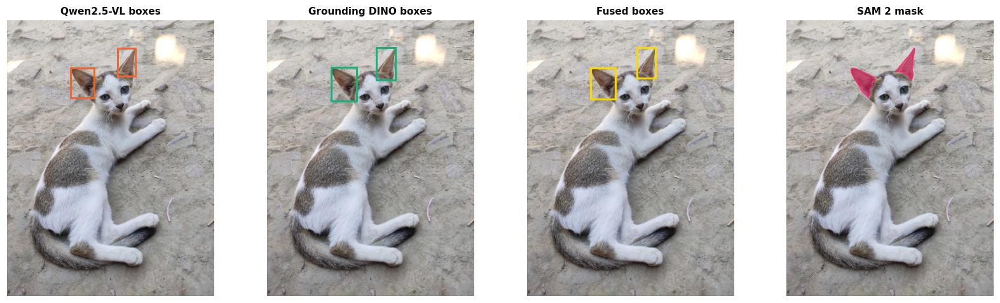

In [22]:
# what each step of System B produces, on one phone photo
r = SYS_B(PHONE_IMGS[3], "Show me the part this cat uses to hear.")
print("prompt understanding:", {k: v for k, v in r["parse"].items() if k != "raw"})
print("VLM boxes:", np.round(r["vlm_boxes"], 0).tolist()); print("DINO boxes:", np.round(r["dino_boxes"], 0).tolist(),
      np.round(r["dino_scores"], 2).tolist())
print("description:", r["description"])
img = r["image"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.4))
def draw(ax, boxes, col, title):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
    for b in boxes:
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=col, lw=2))
draw(axes[0], r["vlm_boxes"], COL_B, "Qwen2.5-VL boxes")
draw(axes[1], r["dino_boxes"], COL_B3, "Grounding DINO boxes")
draw(axes[2], r["boxes"], "gold", "Fused boxes")
axes[3].imshow(overlay(img, r["mask"])); axes[3].axis("off"); axes[3].set_title("SAM 2 mask")
plt.tight_layout(); savefig(fig, "fig06_system_b_steps.png"); plt.show()

---
# 5. Interactive user interface

`app.py` is a Gradio app that shows both systems side by side. The user uploads an image, types a prompt and runs
System A, System B or both. Each side shows the segmentation overlay, the **isolated body part** and the
description, together with how the prompt was understood and how long it took. Start it with `python app.py` and open
`http://127.0.0.1:7860`. The cell below writes the app, starts it in the background, checks that it answers, and calls
the same callback the buttons use, so the displayed outputs are exactly what the UI shows.

In [23]:
%%writefile app.py
"""Interactive UI for both systems.  Run:  python app.py   (then open http://127.0.0.1:7860)"""
import os, sys, time
import numpy as np
import gradio as gr
from bp_common import ROOT, overlay, isolate, SAM2Segmenter

_SYS = {}


def get_systems(which):
    """Load lazily so the UI starts fast; both systems share one SAM 2 model."""
    if "sam" not in _SYS:
        _SYS["sam"] = SAM2Segmenter()
    if which == "A" and "A" not in _SYS:
        from system_a import SystemA
        _SYS["A"] = SystemA(sam=_SYS["sam"])
    if which == "B" and "B" not in _SYS:
        from system_b import SystemB
        _SYS["B"] = SystemB(sam=_SYS["sam"])
    return _SYS[which]


def run_one(which, image, prompt):
    if image is None or not prompt.strip():
        return None, None, "Please upload an image and type a prompt."
    t0 = time.time()
    res = get_systems(which)(image, prompt)
    dt = time.time() - t0
    img, mask = res["image"], res["mask"]
    ov = overlay(img, mask, boxes=res["boxes"])
    part = isolate(img, mask) if mask.any() else None
    q = res.get("parse", {})
    if which == "A":
        understood = f"species = **{res.get('species')}**, part = **{', '.join(res.get('parts', []) or ['-'])}** ({q.get('method')})"
    else:
        understood = f"animal = **{q.get('animal')}**, part = **{q.get('body_part')}**, possible = {q.get('possible')}"
    md = (f"**Prompt understood as:** {understood}  \n**Status:** {res['status']}  \n"
          f"**Time:** {dt:.2f} s\n\n{res.get('description', '')}")
    return ov, part, md


def build_demo():
    examples_dir = ROOT / "phone image"
    examples = [[str(examples_dir / f), p] for f, p in
                [("4.jpg", "Identify the ears of this cat."), ("2.jpg", "Show the nose of this dog."),
                 ("3.jpg", "Show me the part this dog wags."), ("5.jpg", "Show the eyes of the kitten."),
                 ("1.jpg", "Show the wings of this dog.")] if (examples_dir / f).exists()]
    with gr.Blocks(title="Prompt-guided animal body-part segmentation") as demo:
        gr.Markdown("# Prompt-guided animal body-part segmentation\n"
                    "Upload an animal photo, type what you want to see (e.g. *Show the ears of this cat*), and "
                    "compare **System A** (YOLO + SAM 2, no VLM) with **System B** (Qwen2.5-VL + Grounding DINO + SAM 2).")
        with gr.Row():
            image = gr.Image(type="pil", label="Animal image", height=360)
            with gr.Column():
                prompt = gr.Textbox(label="Prompt", placeholder="Show the wings of this bird")
                with gr.Row():
                    btn_a = gr.Button("Run System A (no VLM)")
                    btn_b = gr.Button("Run System B (VLM)", variant="primary")
                    btn_ab = gr.Button("Compare both")
                gr.Examples(examples, [image, prompt])
        with gr.Row():
            with gr.Column():
                gr.Markdown("### System A — YOLO + SAM 2 + predefined description")
                ov_a = gr.Image(label="Segmentation", height=300)
                part_a = gr.Image(label="Isolated body part", height=220)
                txt_a = gr.Markdown()
            with gr.Column():
                gr.Markdown("### System B — Qwen2.5-VL + Grounding DINO + SAM 2")
                ov_b = gr.Image(label="Segmentation", height=300)
                part_b = gr.Image(label="Isolated body part", height=220)
                txt_b = gr.Markdown()
        btn_a.click(lambda i, p: run_one("A", i, p), [image, prompt], [ov_a, part_a, txt_a])
        btn_b.click(lambda i, p: run_one("B", i, p), [image, prompt], [ov_b, part_b, txt_b])
        btn_ab.click(lambda i, p: run_one("A", i, p) + run_one("B", i, p), [image, prompt],
                     [ov_a, part_a, txt_a, ov_b, part_b, txt_b])
    return demo


if __name__ == "__main__":
    build_demo().launch(server_name="127.0.0.1", server_port=int(os.environ.get("PORT", 7860)))

Overwriting app.py


Gradio UI reachable at http://127.0.0.1:7861: True


saved -> outputs\figures\fig08_ui_outputs.png


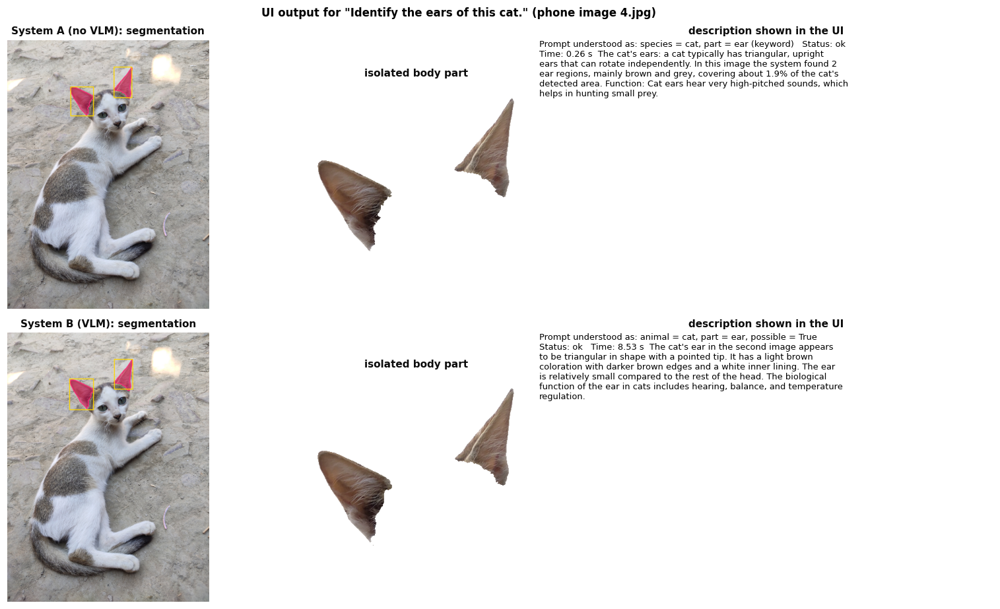

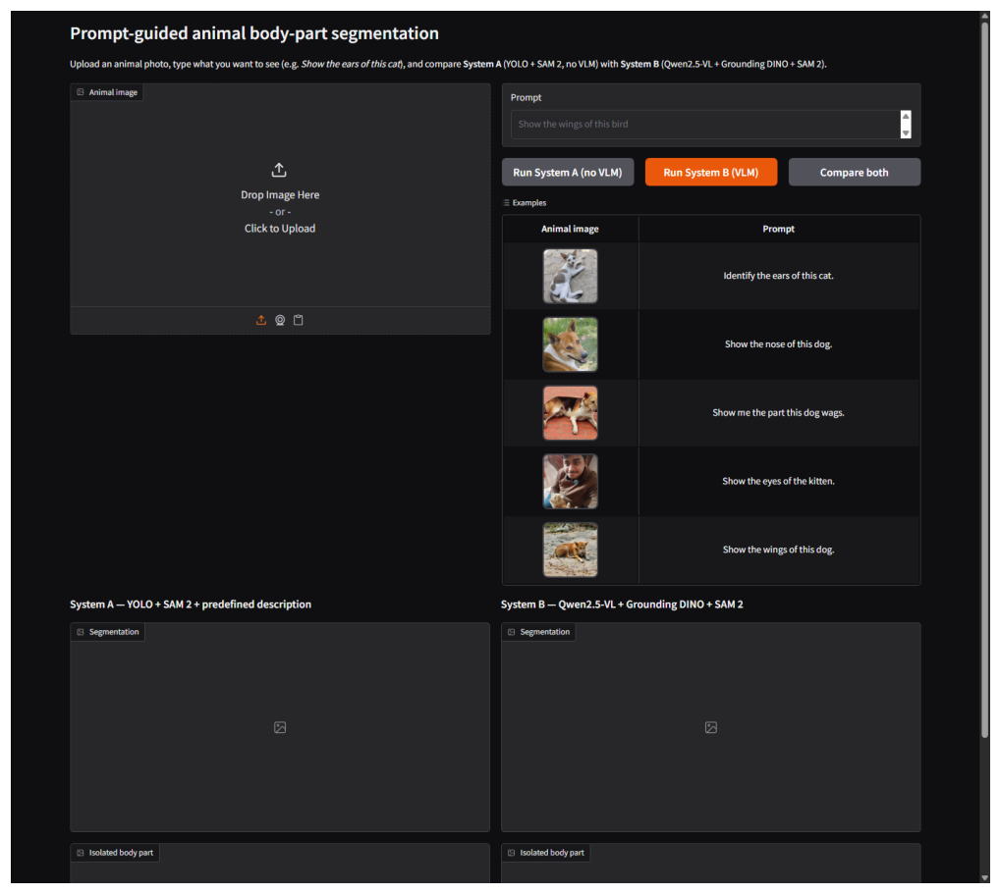

In [24]:
import urllib.request
proc = subprocess.Popen([sys.executable, "app.py"], cwd=ROOT, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                        env={**os.environ, "PORT": "7861"})
ok = False
for _ in range(90):
    try:
        ok = urllib.request.urlopen("http://127.0.0.1:7861", timeout=2).status == 200
        break
    except Exception:
        time.sleep(1)
print("Gradio UI reachable at http://127.0.0.1:7861:", ok)
# screenshot of the running UI with a headless browser (Microsoft Edge ships with Windows)
edge = next((p for p in [r"C:\Program Files (x86)\Microsoft\Edge\Application\msedge.exe",
                         r"C:\Program Files\Microsoft\Edge\Application\msedge.exe"] if Path(p).exists()), None)
if ok and edge:
    subprocess.run([edge, "--headless=new", "--disable-gpu", f"--screenshot={FIG / 'fig07_ui_screenshot.png'}",
                    "--window-size=1400,1250", "--virtual-time-budget=15000", "http://127.0.0.1:7861"], timeout=120)
proc.terminate()

# the UI callback, called directly with the already-loaded systems
import app
app._SYS.update({"sam": SAM, "A": SYS_A, "B": SYS_B})
ui_img = load_image(PHONE / "4.jpg"); ui_prompt = "Identify the ears of this cat."
oa, pa, ta = app.run_one("A", ui_img, ui_prompt)
ob, pb, tb = app.run_one("B", ui_img, ui_prompt)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), gridspec_kw={"width_ratios": [1.3, 0.8, 1.6]})
for row, (o, p, t, name) in enumerate([(oa, pa, ta, "System A (no VLM)"), (ob, pb, tb, "System B (VLM)")]):
    axes[row, 0].imshow(o); axes[row, 0].set_title(f"{name}: segmentation")
    axes[row, 1].imshow(p if p is not None else np.ones((10, 10, 3))); axes[row, 1].set_title("isolated body part")
    axes[row, 2].text(0, 1, "\n".join(__import__("textwrap").wrap(t.replace("**", ""), 70)), va="top", fontsize=8.5,
                      transform=axes[row, 2].transAxes); axes[row, 2].set_title("description shown in the UI")
    for a in axes[row]: a.axis("off")
plt.suptitle(f'UI output for "{ui_prompt}" (phone image 4.jpg)', fontweight="bold")
plt.tight_layout(); savefig(fig, "fig08_ui_outputs.png"); plt.show()
if (FIG / "fig07_ui_screenshot.png").exists():
    plt.figure(figsize=(12, 10.5)); plt.imshow(Image.open(FIG / "fig07_ui_screenshot.png")); plt.axis("off"); plt.show()

---
# 6. Part C — Running both systems on the same images and prompts

Every prompt in the PASCAL-Part test set is answered by:

* **System A** (YOLO boxes → SAM 2), and the ablation **A / YOLO-seg masks** (YOLO's own masks, no SAM 2);
* **System B** with fused boxes, plus its two ablations **B / VLM boxes only** and **B / DINO boxes only**. These reuse the
  same prompt understanding and only change which boxes go to SAM 2.

System B is run once with its visibility rejection switched off (`reject_policy="lenient"`), while its three
signals (*possible*, *visible*, text-only *anatomy check*) are recorded for every prompt. The rejection rules are then
applied afterwards: **B** uses the default rule (reject if not possible, or if not visible *and* the anatomy check says
no), **B / never reject on visibility** uses only the *possible* flag, and **B / reject if not visible** trusts the
visibility flag alone. This shows the trade-off between refusing impossible requests and wrongly refusing real parts
without running the VLM three times.

Descriptions are generated for the first positive prompt of every test image (one per image) to keep the run short.
All outputs are appended to `outputs/predictions/*.jsonl` one prompt at a time, so an interrupted run continues where it
stopped.

In [25]:
def pascal_image(img_id):
    return D.image_path(img_id)

DESCRIBE_QIDS = set(TEST_DF[~TEST_DF.negative].groupby("img_id").qid.min())
t0 = time.time()
res_A = E.run_resumable(SYS_A, TEST, pascal_image, PRED / "A_sam.jsonl", describe_qids=DESCRIBE_QIDS, log_every=100)
print(f"System A done ({time.time() - t0:.0f}s)")

SYS_A.use_sam = False
res_A0 = E.run_resumable(SYS_A, TEST, pascal_image, PRED / "A_yoloseg.jsonl", log_every=0)
SYS_A.use_sam = True
print("System A / YOLO-seg masks done")

def b_extra(res):
    # SAM 2 masks from the VLM-only and DINO-only boxes, stored under the same prompt id (localiser ablation)
    for tag, key in (("vlm", "vlm_boxes"), ("dino", "dino_boxes")):
        m, _ = SAM(res["image"], res.get(key) or [])
        (PRED / f"B_{tag}").mkdir(exist_ok=True)
        np.save(PRED / f"B_{tag}" / f"{res['_qid']}.npy", np.packbits(m))
    return {"vlm_boxes": res.get("vlm_boxes"), "dino_boxes": res.get("dino_boxes"), "dino_scores": res.get("dino_scores")}

def B_lenient(image, prompt, describe=False):
    return SYS_B(image, prompt, describe=describe, reject_policy="lenient")

t0 = time.time()
res_B = E.run_resumable(B_lenient, TEST, pascal_image, PRED / "B_fused.jsonl", describe_qids=DESCRIBE_QIDS,
                        extra=b_extra, log_every=50)
print(f"System B done ({time.time() - t0:.0f}s)")

System A done (0s)
System A / YOLO-seg masks done
System B done (0s)


In [26]:
# per-prompt scoring against the PASCAL-Part ground truth
ANNO_CACHE = {}
def anno(img_id):
    if img_id not in ANNO_CACHE:
        ANNO_CACHE[img_id] = D.load_anno(img_id)[0]
    return ANNO_CACHE[img_id]

B_RULES = {"lenient": lambda p: False,
           "combined": lambda p: (not p.get("visible", True)) and p.get("text_absent", False),
           "strict": lambda p: not p.get("visible", True)}

def score_run(results, jsonl, tag, mask_dir=None, policy=None):
    rows = []
    for r, q in zip(TEST, results):
        shape = tuple(q["shape"])
        if mask_dir is None:
            pred = E.load_mask(jsonl, q["qid"], shape)
        else:
            bits = np.load(mask_dir / f"{q['qid']}.npy")
            pred = np.unpackbits(bits)[: shape[0] * shape[1]].reshape(shape).astype(bool)
        status = q["status"]
        if policy and status not in ("impossible", "not_understood") and B_RULES[policy](q["parse"] or {}):
            pred, status = np.zeros(shape, bool), "impossible"      # the rejection rule applied afterwards
        o = anno(r["img_id"])
        row = {"qid": r["qid"], "system": tag, "img_id": r["img_id"], "species": r["species"], "part": r["part"],
               "style": r["style"], "negative": r["negative"], "status": status, "empty": not pred.any()}
        if r["negative"]:
            row["rejected"] = (not pred.any())
        else:
            gt = E.gt_part_mask(o, r["part"], shape)
            row["iou"], row["dice"] = iou_dice(pred, gt)
            row["correct_part"], row["covered_part"] = E.correct_part(pred, o, r["part"])
            row["hit50"] = row["iou"] >= 0.5
        # did the system *interpret* the prompt correctly (independent of segmentation)?
        if tag.startswith("A"):
            got = q["parts_pred"] or []
            row["interp_ok"] = (q["status"] == "impossible") if r["negative"] else (r["part"] in got)
        else:
            bp = (q["parse"] or {}).get("body_part", "")
            keys = PARSER_NOEMB(bp)["keys"] if bp else []
            got = [resolve_part(k, r["species"]) for k in keys]
            row["interp_ok"] = (status == "impossible") if r["negative"] else (r["part"] in got)
            row["vlm_animal"] = (q["parse"] or {}).get("animal")
        rows.append(row)
    return pd.DataFrame(rows)

from system_a import PromptParser
PARSER_NOEMB = PromptParser(use_embeddings=False)     # maps the VLM's free-text part name onto the 15 classes
SC = pd.concat([score_run(res_A, PRED / "A_sam.jsonl", "A"),
                score_run(res_A0, PRED / "A_yoloseg.jsonl", "A / YOLO-seg masks"),
                score_run(res_B, PRED / "B_fused.jsonl", "B", policy="combined"),
                score_run(res_B, PRED / "B_fused.jsonl", "B / VLM boxes only", PRED / "B_vlm", policy="combined"),
                score_run(res_B, PRED / "B_fused.jsonl", "B / DINO boxes only", PRED / "B_dino", policy="combined"),
                score_run(res_B, PRED / "B_fused.jsonl", "B / never reject on visibility", policy="lenient"),
                score_run(res_B, PRED / "B_fused.jsonl", "B / reject if not visible", policy="strict")],
               ignore_index=True)
for c in ("correct_part", "hit50", "rejected"):
    SC[c] = SC[c].astype(float)                      # True/False/NaN -> 1/0/NaN so that means are well defined
SC.to_csv(RES / "per_prompt_scores.csv", index=False)
print(SC.groupby("system").size())

system
A                                 400
A / YOLO-seg masks                400
B                                 400
B / DINO boxes only               400
B / VLM boxes only                400
B / never reject on visibility    400
B / reject if not visible         400
dtype: int64


---
# 7. Part C — Results

## 7.1 Prompt following

Two separate questions are asked:

* **Interpretation accuracy**: did the system understand *which* part was meant (or that the request is impossible)?
  For System A this is the parser's output; for System B the VLM's `body_part`, mapped onto the 15 classes.
* **Correct-part rate**: does the predicted mask actually lie on the requested part? The mask's pixels are assigned to
  the annotated parts they cover, and the request counts as followed if the requested part receives the most pixels.
  For impossible prompts the correct behaviour is an empty result (**rejection rate**).

,interpretation acc. (all prompts),correct-part rate (positive prompts),hit rate IoU>=0.5,empty answer (positive prompts),rejection rate (impossible prompts)
system,,,,,
A,0.950,0.714,0.592,0.156,1.000
A / YOLO-seg masks,0.950,0.733,0.542,0.156,1.000
B,0.972,0.686,0.439,0.031,0.925
B / DINO boxes only,0.972,0.183,0.153,0.411,0.950
B / VLM boxes only,0.972,0.692,0.442,0.031,0.925
B / never reject on visibility,0.920,0.692,0.442,0.000,0.400
B / reject if not visible,0.972,0.628,0.403,0.139,0.925


correct-part rate by prompt style:


,direct,indirect,synonym,impossible (rejection)
system,,,,
A,0.725,0.675,0.742,1.000
B,0.683,0.683,0.692,0.925


interpretation accuracy by prompt style:


style,direct,impossible,indirect,synonym
system,,,,
A,1.0,1.000,0.833,1.00
B,1.0,0.925,0.983,0.95


saved -> outputs\figures\fig09_prompt_following.png


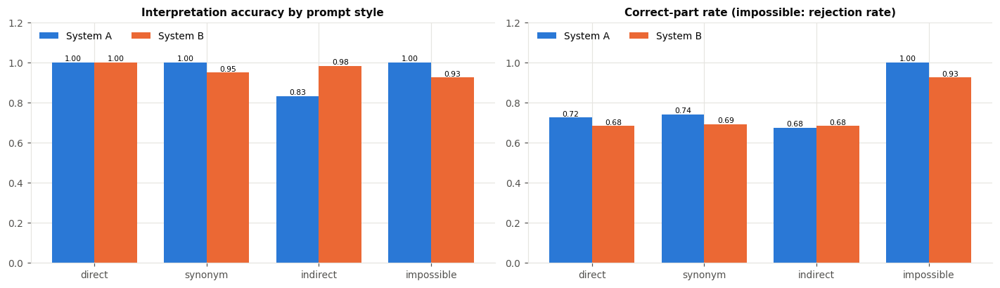

,real parts wrongly refused,impossible requests refused,mean IoU (positive prompts)
system,,,
A,0.008,1.000,0.510
B / never reject on visibility,0.000,0.400,0.445
B,0.031,0.925,0.441
B / reject if not visible,0.139,0.925,0.404


In [27]:
MAIN = ["A", "B"]
pos = SC[~SC.negative]; neg = SC[SC.negative]
pf = pd.DataFrame({
    "interpretation acc. (all prompts)": SC.groupby("system").interp_ok.mean(),
    "correct-part rate (positive prompts)": pos.groupby("system").correct_part.mean(),
    "hit rate IoU>=0.5": pos.groupby("system").hit50.mean(),
    "empty answer (positive prompts)": pos.groupby("system").empty.mean(),
    "rejection rate (impossible prompts)": neg.groupby("system").rejected.mean(),
}).round(3)
display(pf); pf.to_csv(RES / "prompt_following.csv")

by_style = pd.concat([SC[SC["style"] != "impossible"].groupby(["system", "style"]).correct_part.mean().unstack(),
                      neg.groupby("system").rejected.mean().rename("impossible (rejection)")], axis=1).round(3)
interp_style = SC.groupby(["system", "style"]).interp_ok.mean().unstack().round(3)
print("correct-part rate by prompt style:"); display(by_style.loc[MAIN])
print("interpretation accuracy by prompt style:"); display(interp_style.loc[MAIN])
by_style.to_csv(RES / "prompt_following_by_style.csv"); interp_style.to_csv(RES / "interpretation_by_style.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
styles = ["direct", "synonym", "indirect", "impossible"]
x = np.arange(len(styles))
for k, (sysname, col) in enumerate([("A", COL_A), ("B", COL_B)]):
    axes[0].bar(x + (k - 0.5) * 0.38, [interp_style.loc[sysname, s] for s in styles], 0.38, color=col, label=f"System {sysname}")
    vals = [by_style.loc[sysname, s] for s in styles[:3]] + [by_style.loc[sysname, "impossible (rejection)"]]
    axes[1].bar(x + (k - 0.5) * 0.38, vals, 0.38, color=col, label=f"System {sysname}")
for ax, t in zip(axes, ["Interpretation accuracy by prompt style", "Correct-part rate (impossible: rejection rate)"]):
    ax.set_xticks(x, styles); ax.set_ylim(0, 1.2); ax.set_title(t); ax.legend(ncol=2, loc="upper left")
for ax in axes:
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); savefig(fig, "fig09_prompt_following.png"); plt.show()

# System B's refusal rules on the test set: real parts wrongly refused vs impossible requests caught
REJ = pd.DataFrame({
    "real parts wrongly refused": pos.assign(ref=pos.status == "impossible").groupby("system").ref.mean(),
    "impossible requests refused": neg.groupby("system").rejected.mean(),
    "mean IoU (positive prompts)": pos.groupby("system").iou.mean()}).round(3)
REJ = REJ.loc[["A", "B / never reject on visibility", "B", "B / reject if not visible"]]
display(REJ); REJ.to_csv(RES / "rejection_tradeoff.csv")

## 7.2 Segmentation quality (IoU and Dice against PASCAL-Part ground truth)

IoU and Dice are computed per positive prompt against the union of all ground-truth instances of the requested part
on the single animal in the image. A prompt the system answers with nothing scores 0. Three views are given: overall,
**only where the part was correctly interpreted** (pure segmentation quality), and per part and species.

In [28]:
seg = pos.groupby("system").agg(IoU=("iou", "mean"), Dice=("dice", "mean"), median_IoU=("iou", "median"), n=("iou", "size"))
seg_ok = pos[pos.interp_ok].groupby("system").agg(IoU_if_understood=("iou", "mean"), Dice_if_understood=("dice", "mean"))
SEG = seg.join(seg_ok).round(3)
order = ["A", "A / YOLO-seg masks", "B", "B / VLM boxes only", "B / DINO boxes only",
         "B / never reject on visibility", "B / reject if not visible"]
display(SEG.loc[order]); SEG.to_csv(RES / "segmentation_overall.csv")

per_part = pos.pivot_table(index="part", columns="system", values="iou", aggfunc="mean")[order].round(3)
per_part["n"] = pos[pos.system == "A"].groupby("part").size()
per_species = pos.pivot_table(index="species", columns="system", values="iou", aggfunc="mean")[order].round(3)
per_style = pos.pivot_table(index="style", columns="system", values="iou", aggfunc="mean")[order].round(3)
display(per_part); display(per_species); display(per_style)
per_part.to_csv(RES / "iou_per_part.csv"); per_species.to_csv(RES / "iou_per_species.csv"); per_style.to_csv(RES / "iou_per_style.csv")

,IoU,Dice,median_IoU,n,IoU_if_understood,Dice_if_understood
system,,,,,,
A,0.510,0.598,0.611,360,0.538,0.629
A / YOLO-seg masks,0.471,0.570,0.557,360,0.497,0.601
B,0.441,0.545,0.446,360,0.444,0.550
B / VLM boxes only,0.441,0.545,0.448,360,0.445,0.550
B / DINO boxes only,0.163,0.210,0.018,360,0.162,0.208
B / never reject on visibility,0.445,0.551,0.447,360,0.449,0.557
B / reject if not visible,0.404,0.498,0.401,360,0.408,0.504


system,A,A / YOLO-seg masks,B,B / VLM boxes only,B / DINO boxes only,B / never reject on visibility,B / reject if not visible,n
part,,,,,,,,
beak,0.090,0.091,0.399,0.382,0.179,0.399,0.399,10
ear,0.652,0.631,0.560,0.561,0.172,0.560,0.522,36
eye,0.454,0.413,0.497,0.497,0.062,0.497,0.443,35
foot,0.190,0.155,0.615,0.603,0.128,0.615,0.520,4
head,0.818,0.550,0.566,0.571,0.312,0.566,0.548,37
hoof,0.262,0.258,0.367,0.367,0.011,0.367,0.302,8
horn,0.499,0.446,0.672,0.761,0.149,0.672,0.672,7
leg,0.548,0.403,0.478,0.474,0.167,0.478,0.372,33
muzzle,0.498,0.541,0.326,0.325,0.097,0.326,0.303,36


system,A,A / YOLO-seg masks,B,B / VLM boxes only,B / DINO boxes only,B / never reject on visibility,B / reject if not visible
species,,,,,,,
bird,0.199,0.173,0.414,0.414,0.196,0.414,0.371
cat,0.512,0.479,0.457,0.458,0.132,0.461,0.427
cow,0.576,0.535,0.457,0.461,0.146,0.457,0.442
dog,0.593,0.544,0.451,0.444,0.212,0.460,0.414
horse,0.449,0.442,0.365,0.371,0.098,0.365,0.289
sheep,0.482,0.402,0.419,0.439,0.138,0.420,0.382


system,A,A / YOLO-seg masks,B,B / VLM boxes only,B / DINO boxes only,B / never reject on visibility,B / reject if not visible
style,,,,,,,
direct,0.507,0.486,0.502,0.502,0.160,0.503,0.457
indirect,0.508,0.442,0.421,0.423,0.186,0.421,0.389
synonym,0.517,0.484,0.398,0.398,0.142,0.411,0.365


saved -> outputs\figures\fig10_segmentation_quality.png


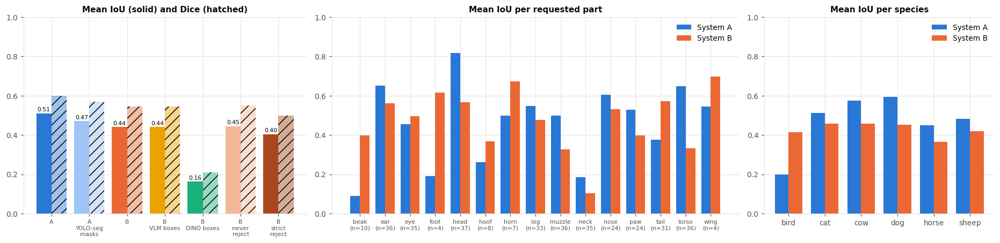

saved -> outputs\figures\fig11_iou_distribution.png


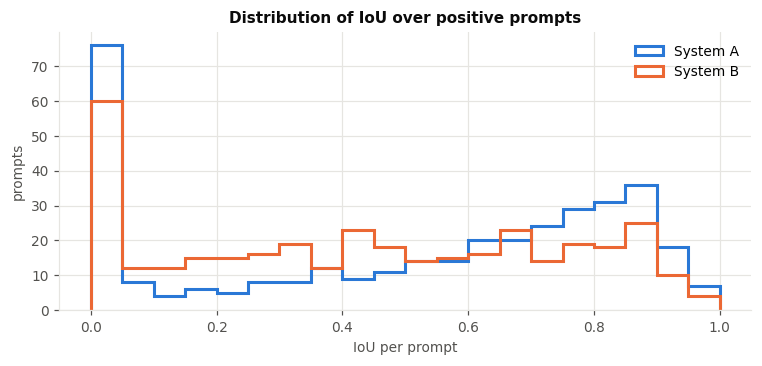

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.6, 2.3, 1.3]})
cols = {"A": COL_A, "A / YOLO-seg masks": "#9ec5f4", "B": COL_B, "B / VLM boxes only": COL_B2,
        "B / DINO boxes only": COL_B3, "B / never reject on visibility": "#f4b896", "B / reject if not visible": "#a8461f"}
ax = axes[0]
x = np.arange(len(order))
ax.bar(x - 0.2, SEG.loc[order, "IoU"], 0.4, color=[cols[o] for o in order])
ax.bar(x + 0.2, SEG.loc[order, "Dice"], 0.4, color=[cols[o] for o in order], alpha=0.45, hatch="//")
labels = ["A", "A\nYOLO-seg\nmasks", "B", "B\nVLM boxes", "B\nDINO boxes", "B\nnever\nreject", "B\nstrict\nreject"]
ax.set_xticks(x, labels, fontsize=7); ax.set_ylim(0, 1)
ax.set_title("Mean IoU (solid) and Dice (hatched)")
for i, o in enumerate(order): ax.text(i - 0.2, SEG.loc[o, "IoU"] + 0.01, f"{SEG.loc[o, 'IoU']:.2f}", ha="center", fontsize=7)
ax = axes[1]
pp = per_part.drop(columns="n").dropna(how="all")
x = np.arange(len(pp))
for k, (s, c) in enumerate([("A", COL_A), ("B", COL_B)]):
    ax.bar(x + (k - 0.5) * 0.38, pp[s], 0.38, color=c, label=f"System {s}")
ax.set_xticks(x, [f"{p}\n(n={int(per_part.loc[p, 'n'])})" for p in pp.index], fontsize=7); ax.set_ylim(0, 1)
ax.set_title("Mean IoU per requested part"); ax.legend()
ax = axes[2]
x = np.arange(len(per_species))
for k, (s, c) in enumerate([("A", COL_A), ("B", COL_B)]):
    ax.bar(x + (k - 0.5) * 0.38, per_species[s], 0.38, color=c, label=f"System {s}")
ax.set_xticks(x, per_species.index); ax.set_ylim(0, 1); ax.set_title("Mean IoU per species"); ax.legend()
plt.tight_layout(); savefig(fig, "fig10_segmentation_quality.png"); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, 1, 21)
for s, c in [("A", COL_A), ("B", COL_B)]:
    ax.hist(pos[pos.system == s].iou, bins, histtype="step", lw=2, color=c, label=f"System {s}")
ax.set_xlabel("IoU per prompt"); ax.set_ylabel("prompts"); ax.legend(); ax.set_title("Distribution of IoU over positive prompts")
plt.tight_layout(); savefig(fig, "fig11_iou_distribution.png"); plt.show()

saved -> outputs\figures\fig12_pascal_examples.png


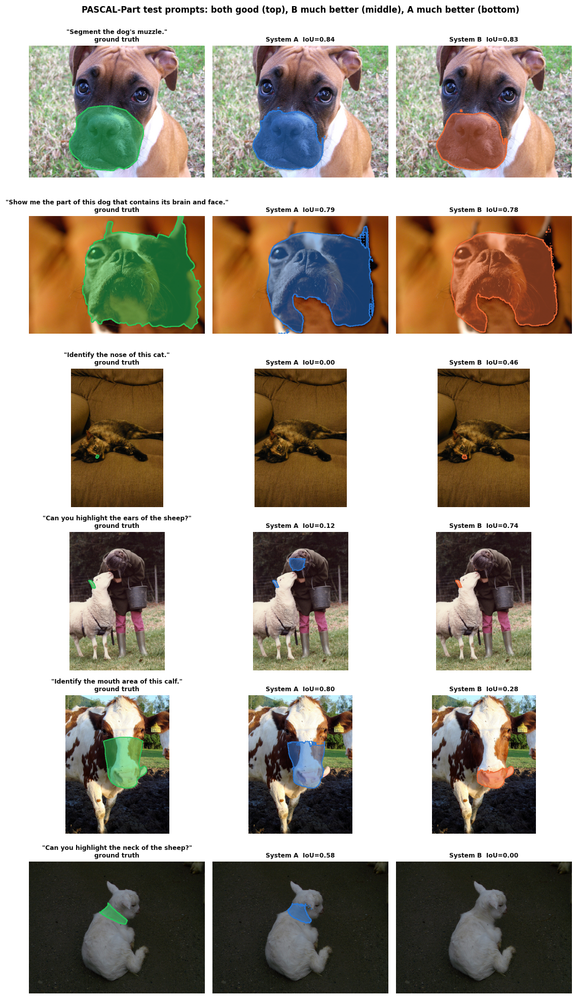

prompts where both IoU>0.6: 96, B better by >0.4: 32, A better by >0.4: 60
styles where B is much better: {'direct': 13, 'indirect': 11, 'synonym': 8}
styles where A is much better: {'indirect': 23, 'synonym': 20, 'direct': 17}


In [30]:
# qualitative PASCAL-Part examples: GT vs System A vs System B on the same prompt
def show_examples(qids, name, title):
    fig, axes = plt.subplots(len(qids), 3, figsize=(10, 3.0 * len(qids)))
    for row, qid in enumerate(qids):
        r = TEST[qid]; img = np.asarray(Image.open(D.image_path(r["img_id"])).convert("RGB")); o = anno(r["img_id"])
        gt = E.gt_part_mask(o, r["part"], img.shape[:2])
        ma = E.load_mask(PRED / "A_sam.jsonl", qid, img.shape[:2]); mb = E.load_mask(PRED / "B_fused.jsonl", qid, img.shape[:2])
        if B_RULES["combined"](res_B[qid]["parse"] or {}):
            mb[:] = False                                          # System B's default refusal rule
        ia, ib = iou_dice(ma, gt)[0], iou_dice(mb, gt)[0]
        for ax, m, t, c in [(axes[row, 0], gt, f'"{r["prompt"]}"\nground truth', (40, 200, 90)),
                            (axes[row, 1], ma, f"System A  IoU={ia:.2f}", (42, 120, 214)),
                            (axes[row, 2], mb, f"System B  IoU={ib:.2f}", (235, 104, 52))]:
            ax.imshow(overlay(img, m, colour=c)); ax.set_title(t, fontsize=8); ax.axis("off")
    plt.tight_layout(rect=(0, 0, 1, 0.975)); plt.suptitle(title, fontweight="bold", y=0.995); savefig(fig, name); plt.show()

piv = SC[SC.system.isin(["A", "B"]) & ~SC.negative].pivot_table(index="qid", columns="system", values="iou")
piv = piv.join(TEST_DF.set_index("qid")[["style", "species"]])
rs = np.random.default_rng(1)
both_good = piv[(piv.A > 0.6) & (piv.B > 0.6)].index.tolist()
b_better = piv[(piv.B - piv.A) > 0.4].index.tolist()
a_better = piv[(piv.A - piv.B) > 0.4].index.tolist()
pick = lambda l, k: sorted(rs.choice(l, min(k, len(l)), replace=False).tolist()) if l else []
show_examples(pick(both_good, 2) + pick(b_better, 2) + pick(a_better, 2), "fig12_pascal_examples.png",
              "PASCAL-Part test prompts: both good (top), B much better (middle), A much better (bottom)")
print(f"prompts where both IoU>0.6: {len(both_good)}, B better by >0.4: {len(b_better)}, A better by >0.4: {len(a_better)}")
print("styles where B is much better:", piv.loc[b_better, "style"].value_counts().to_dict())
print("styles where A is much better:", piv.loc[a_better, "style"].value_counts().to_dict())

## 7.3 Description quality

Each description (one per test image, both systems) is scored with a simple, automatic checklist:

| criterion | meaning |
|---|---|
| mentions part | the requested part (or a synonym) is named |
| mentions species | the correct animal is named |
| states function | a biological function is given (*used for*, *helps*, *allows* …) |
| colour correct | at least one colour word agrees with the colour measured on the **ground-truth** region |
| concise | 15–90 words |
| wrong species | another animal is named (penalty) |

**Context awareness** is measured separately. For each part, the descriptions written for *different* images are
embedded with MiniLM and their average pairwise cosine similarity is computed. A system that writes the same text for
every cat ear scores close to 1; a system that describes what it actually sees scores lower.

,mentions_part,mentions_species,states_function,colour_correct,concise,wrong_species,score,n_words,same-part description similarity (lower = more image-specific)
system,,,,,,,,,
A,1.000,1.000,0.783,0.75,0.783,0.0,4.317,41.550,0.876
B,0.983,0.958,0.967,0.65,0.925,0.0,4.483,60.908,0.766


,mentions_part (answered only),mentions_species (answered only),states_function (answered only),colour_correct (answered only),concise (answered only),score (answered only)
system,,,,,,
A,1.0,1.000,1.000,0.957,1.000,4.957
B,1.0,0.975,0.983,0.661,0.941,4.559


saved -> outputs\figures\fig13_description_quality.png


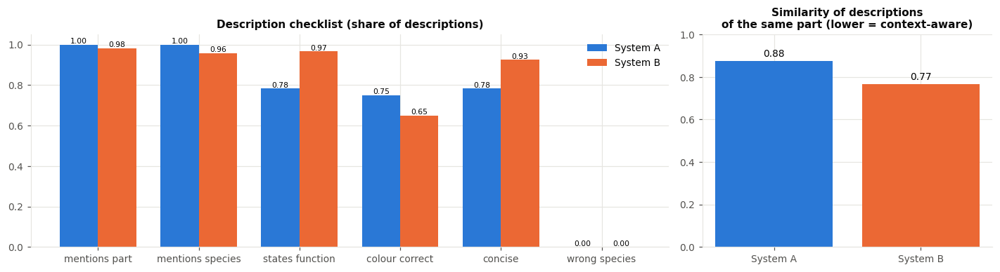


### Can you highlight the nose of the cat?  (2008_000222)
A: The cat's nose: a cat typically has a small triangular pink or dark nose. In this image the system found 1 nose region, mainly reddish brown and light brown, covering about 0.2% of the cat's detected area. Function: The nose is used for breathing and for a very sensitive sense of smell.
B: The cat's nose in the second image appears to be small, pink, and slightly moist. The nose serves as a crucial sensory organ for the cat, allowing it to detect scents and navigate its environment.

### Show the eyes of this cat.  (2008_001374)
A: The cat's eyes: a cat typically has large eyes with vertical slit pupils. In this image the system found 2 eye regions, mainly light brown and tan, covering about 0.2% of the cat's detected area. Function: Cat eyes see well in very low light, which suits hunting at dawn and dusk.
B: The cat's eye in the second image appears to be large, round, and has a yellowish hue with a clear, reflective surfa

In [31]:
from sentence_transformers import SentenceTransformer
EMB = SYS_A.parser.emb
drows = []
for tag, results in (("A", res_A), ("B", res_B)):
    for r, q in zip(TEST, results):
        if r["qid"] not in DESCRIBE_QIDS or r["negative"]:      # only the prompts selected for description
            continue
        status, text = q["status"], q["description"]
        if tag == "B" and status == "ok" and B_RULES["combined"](q["parse"] or {}):   # B's default refusal rule
            status, text = "impossible", "Nothing was segmented."
        img = np.asarray(Image.open(D.image_path(r["img_id"])).convert("RGB"))
        gt = E.gt_part_mask(anno(r["img_id"]), r["part"], img.shape[:2])
        s = E.description_scores(text, r["species"], r["part"], img, gt)
        drows.append({"system": tag, "qid": r["qid"], "species": r["species"], "part": r["part"], "status": status,
                      "text": text, **s})
DS = pd.DataFrame(drows)
crit = ["mentions_part", "mentions_species", "states_function", "colour_correct", "concise"]
DS["score"] = DS[crit].sum(1) - DS.wrong_species
desc = DS.groupby("system")[crit + ["wrong_species", "score", "n_words"]].mean().round(3)
answered = DS[DS.status == "ok"].groupby("system")[crit + ["score"]].mean().round(3).add_suffix(" (answered only)")

def context_similarity(df):
    out = {}
    for s, g in df.groupby("system"):
        sims = []
        for p, gp in g[g.status == "ok"].groupby("part"):
            if len(gp) < 2: continue
            v = EMB.encode(gp.text.tolist(), normalize_embeddings=True)
            S = v @ v.T
            sims += S[np.triu_indices(len(gp), 1)].tolist()
        out[s] = np.mean(sims)
    return pd.Series(out, name="same-part description similarity (lower = more image-specific)")
desc = desc.join(context_similarity(DS).round(3))
display(desc); display(answered)
DS.to_csv(RES / "descriptions_scored.csv", index=False); desc.to_csv(RES / "description_quality.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
x = np.arange(len(crit) + 1)
for k, (s, c) in enumerate([("A", COL_A), ("B", COL_B)]):
    axes[0].bar(x + (k - 0.5) * 0.38, [desc.loc[s, cc] for cc in crit + ["wrong_species"]], 0.38, color=c, label=f"System {s}")
axes[0].set_xticks(x, [c.replace("_", " ") for c in crit + ["wrong_species"]]); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Description checklist (share of descriptions)"); axes[0].legend()
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.2f", fontsize=7)
sims = desc.iloc[:, -1]
axes[1].bar(["System A", "System B"], sims.loc[["A", "B"]], color=[COL_A, COL_B])
axes[1].set_ylim(0, 1); axes[1].set_title("Similarity of descriptions\nof the same part (lower = context-aware)")
for i, v in enumerate(sims.loc[["A", "B"]]): axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.tight_layout(); savefig(fig, "fig13_description_quality.png"); plt.show()

ex = DS.pivot_table(index="qid", columns="system", values="text", aggfunc="first").dropna().head(4)
for qid, row in ex.iterrows():
    print(f"\n### {TEST[qid]['prompt']}  ({TEST[qid]['img_id']})\nA: {row['A']}\nB: {row['B']}")

## 7.4 Computational requirements

,parameters (M),GPU weights (GB),extra GPU memory at inference (GB),load time (s),"per prompt, no description (s)",description (s),stage: parse,stage: detect_animal,stage: detect_parts,stage: segment,stage: describe,stage: understand,stage: ground_vlm,stage: ground_dino
A,133.728,0.545,0.341,8.509,0.123,0.001,0.0,0.014,0.013,0.127,0.002,NaN,NaN,NaN
B,4067.786,7.870,1.195,15.304,4.223,2.790,NaN,NaN,NaN,0.126,3.162,1.653,2.161,0.39


,system,model,params (M)
0,A,YOLO11m (animals),20.09
1,A,YOLO11s-seg (parts),10.07
2,A,MiniLM (text only),22.71
3,A,SAM 2.1-B,80.85
4,B,Qwen2.5-VL-3B,3754.62
5,B,Grounding DINO-B,232.31
6,B,SAM 2.1-B,80.85


saved -> outputs\figures\fig14_compute.png


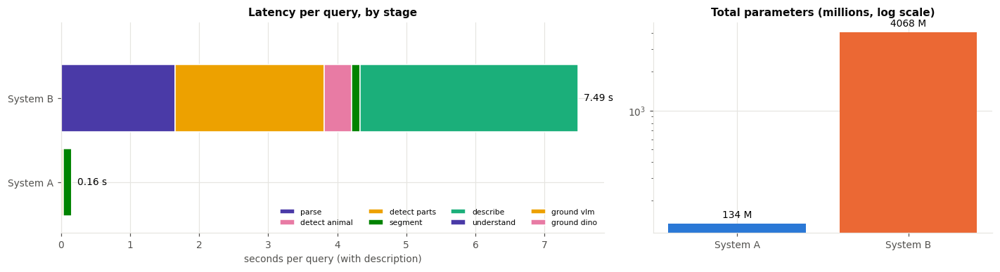

In [32]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())
params = {
    "A": {"YOLO11m (animals)": n_params(SYS_A.det.model), "YOLO11s-seg (parts)": n_params(SYS_A.parts.model),
          "MiniLM (text only)": n_params(SYS_A.parser.emb), "SAM 2.1-B": n_params(SAM.model.model)},
    "B": {"Qwen2.5-VL-3B": n_params(SYS_B.vlm), "Grounding DINO-B": n_params(SYS_B.gd), "SAM 2.1-B": n_params(SAM.model.model)},
}
lat = {}
for tag, results in (("A", res_A), ("B", res_B)):
    t = pd.DataFrame([q["time"] for q in results]).fillna(0)
    desc_t = t.loc[[i for i, q in enumerate(results) if q.get("description")], "describe"].mean() if "describe" in t else 0
    lat[tag] = {"per prompt, no description (s)": t.drop(columns=["describe"], errors="ignore").sum(1).mean(),
                "description (s)": desc_t, **{f"stage: {k}": t.loc[t[k] > 0, k].mean() for k in t.columns}}
# peak GPU memory of one full query (with description) per system, on a phone photo
peak = {}
for tag, sysm in (("A", SYS_A), ("B", SYS_B)):
    torch.cuda.synchronize(); base = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    sysm(PHONE_IMGS[2], "Show the legs of this dog.")
    peak[tag] = (torch.cuda.max_memory_allocated() - base) / 2**30
COMP = pd.DataFrame({
    "parameters (M)": {k: sum(v.values()) / 1e6 for k, v in params.items()},
    "GPU weights (GB)": {k: LOAD[k]["weights_GB"] for k in LOAD},
    "extra GPU memory at inference (GB)": peak,
    "load time (s)": {k: LOAD[k]["load_s"] for k in LOAD},
}).join(pd.DataFrame(lat).T).round(3)
display(COMP); COMP.to_csv(RES / "compute.csv")
display(pd.DataFrame([(s, m, v / 1e6) for s, d in params.items() for m, v in d.items()], columns=["system", "model", "params (M)"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
STAGE_COL = {"parse": PALETTE[6], "understand": PALETTE[6], "detect_animal": PALETTE[4], "detect_parts": PALETTE[3],
             "ground_vlm": PALETTE[3], "ground_dino": PALETTE[4], "segment": PALETTE[5], "describe": PALETTE[2]}
stages = {"A": ["parse", "detect_animal", "detect_parts", "segment", "describe"],
          "B": ["understand", "ground_vlm", "ground_dino", "segment", "describe"]}
for i, s in enumerate(["A", "B"]):
    left = 0
    for st in stages[s]:
        v = lat[s].get(f"stage: {st}", 0) or 0
        axes[0].barh(i, v, left=left, color=STAGE_COL[st], edgecolor="white", label=st.replace("_", " "))
        left += v
    axes[0].text(left + 0.08, i, f"{left:.2f} s", va="center")
h, l = axes[0].get_legend_handles_labels()
uniq = dict(zip(l, h))
axes[0].legend(uniq.values(), uniq.keys(), fontsize=7, ncol=4, loc="lower right")
axes[0].set_yticks([0, 1], ["System A", "System B"]); axes[0].set_xlabel("seconds per query (with description)")
axes[0].set_title("Latency per query, by stage"); axes[0].set_ylim(-0.6, 1.9)
axes[1].bar(["System A", "System B"], COMP.loc[["A", "B"], "parameters (M)"], color=[COL_A, COL_B]); axes[1].set_yscale("log")
axes[1].set_title("Total parameters (millions, log scale)")
for i, v in enumerate(COMP.loc[["A", "B"], "parameters (M)"]): axes[1].text(i, v * 1.1, f"{v:.0f} M", ha="center")
plt.tight_layout(); savefig(fig, "fig14_compute.png"); plt.show()

## 7.5 Phone photographs: both systems on the same prompts

The 25 phone prompts (§2) are run through both systems with descriptions. One figure per photograph shows, for every
prompt, each system's segmentation, its isolated part and the start of its description. All descriptions are saved
in full in `outputs/results/phone_outputs.csv`, and the isolated parts as PNG files in `outputs/predictions/phone/`.

In [33]:
import textwrap
PH_OUT = PRED / "phone"; PH_OUT.mkdir(exist_ok=True)
ph_file = RES / "phone_outputs.csv"
PH_RES = {}
rows = []
for r in PHONE_DF.itertuples():
    for tag, sysm in (("A", SYS_A), ("B", SYS_B)):
        res = sysm(PHONE / r.image, r.prompt)
        PH_RES[(r.qid, tag)] = res
        part = isolate(res["image"], res["mask"]) if res["mask"].any() else None
        if part is not None:
            Image.fromarray(part).save(PH_OUT / f"q{r.qid:02d}_{tag}_{r.image[:-4]}_{r.part}.png")
        q = res.get("parse", {})
        rows.append({"qid": r.qid, "image": r.image, "prompt": r.prompt, "style": r.style, "intended part": r.part,
                     "system": tag, "status": res["status"],
                     "understood as": ", ".join(res.get("parts") or []) if tag == "A" else q.get("body_part"),
                     "n boxes": len(res["boxes"]), "mask px %": round(100 * res["mask"].mean(), 2),
                     "time (s)": round(sum(res["time"].values()), 2), "description": res.get("description", "")})
PH = pd.DataFrame(rows); PH.to_csv(ph_file, index=False)
display(PH[["qid", "image", "prompt", "system", "status", "understood as", "n boxes", "time (s)"]])

,qid,image,prompt,system,status,understood as,n boxes,time (s)
0,0,1.jpg,Show the ears of this dog.,A,ok,ear,2,0.17
1,0,1.jpg,Show the ears of this dog.,B,ok,ear,2,11.79
2,1,1.jpg,Where is the dog's tail?,A,ok,tail,1,0.15
3,1,1.jpg,Where is the dog's tail?,B,ok,tail,1,7.37
4,2,1.jpg,Segment the puppy's snout.,A,ok,muzzle,1,0.13
5,2,1.jpg,Segment the puppy's snout.,B,ok,snout,1,8.99
6,3,1.jpg,Show me the part this dog uses to smell.,A,ok,nose,1,0.16
7,3,1.jpg,Show me the part this dog uses to smell.,B,ok,nose,1,6.99
8,4,1.jpg,Show the wings of this dog.,A,impossible,wing,0,0.02
9,4,1.jpg,Show the wings of this dog.,B,impossible,wings,0,1.68


saved -> outputs\figures\fig15_phone_1.png


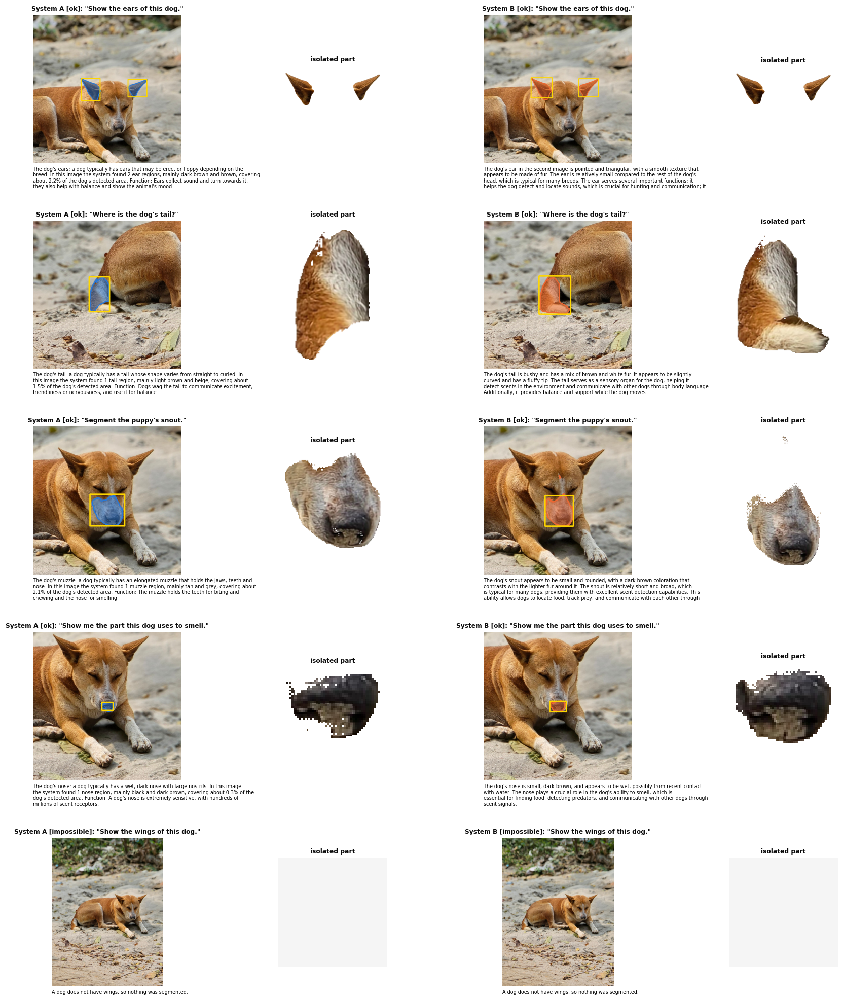

saved -> outputs\figures\fig15_phone_2.png


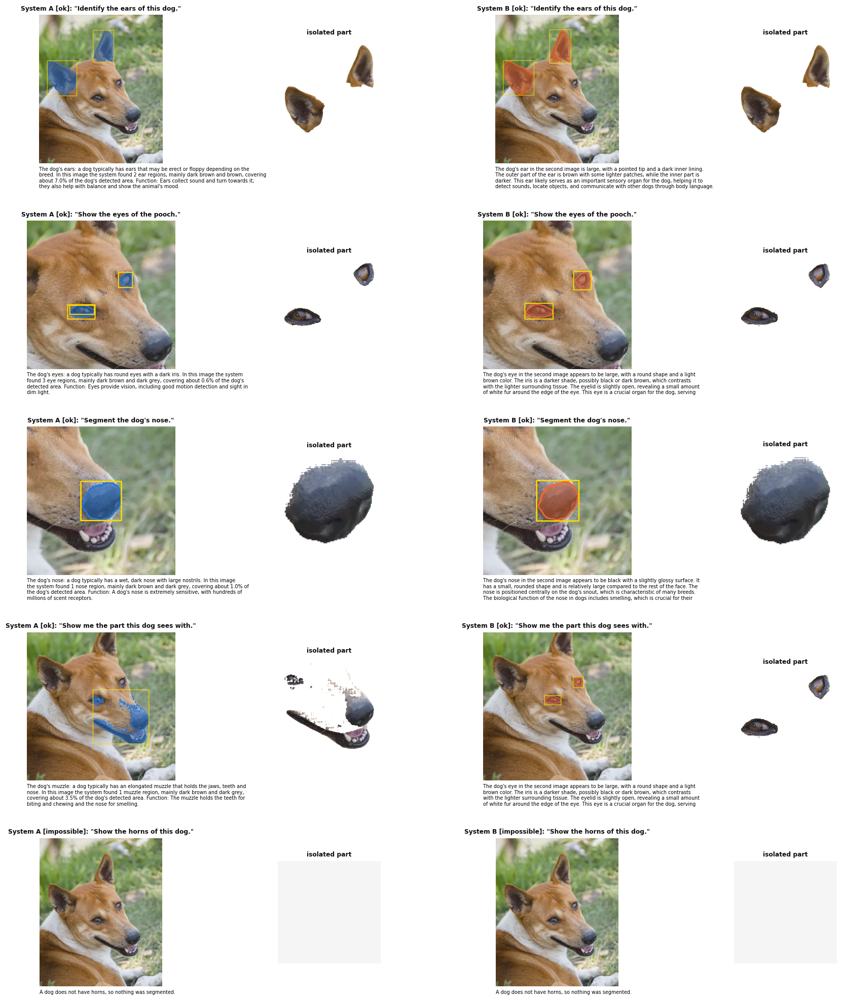

saved -> outputs\figures\fig15_phone_3.png


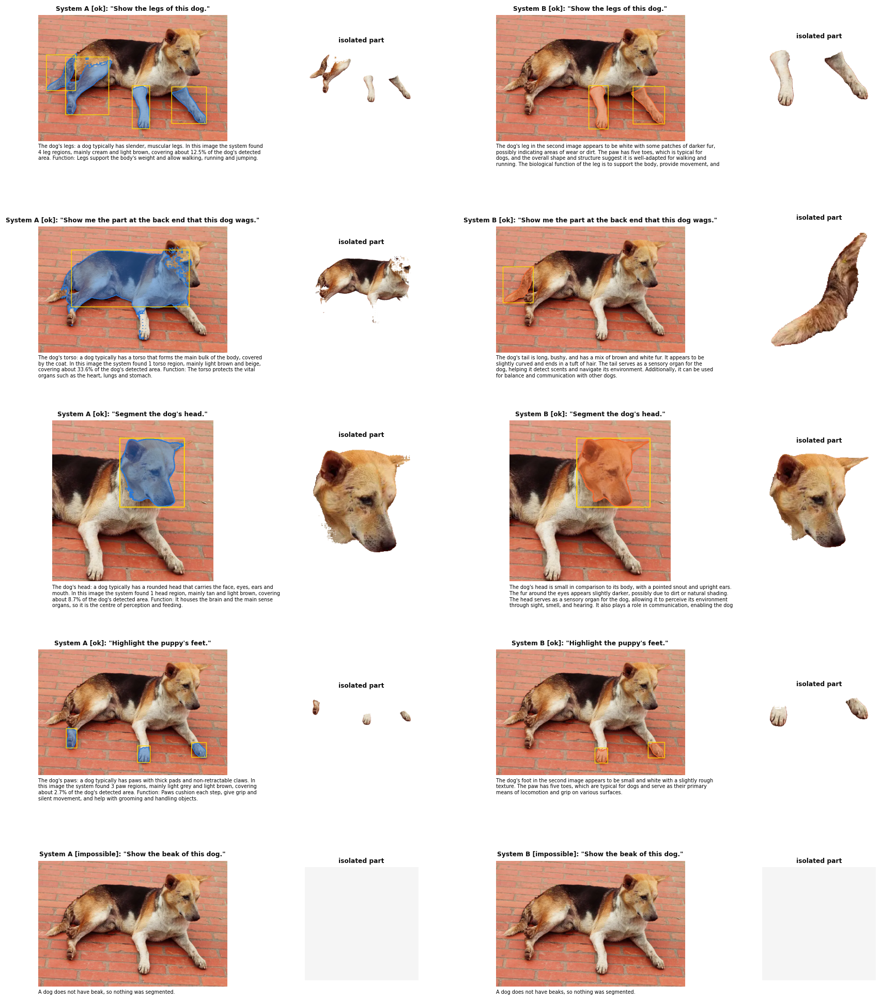

saved -> outputs\figures\fig15_phone_4.png


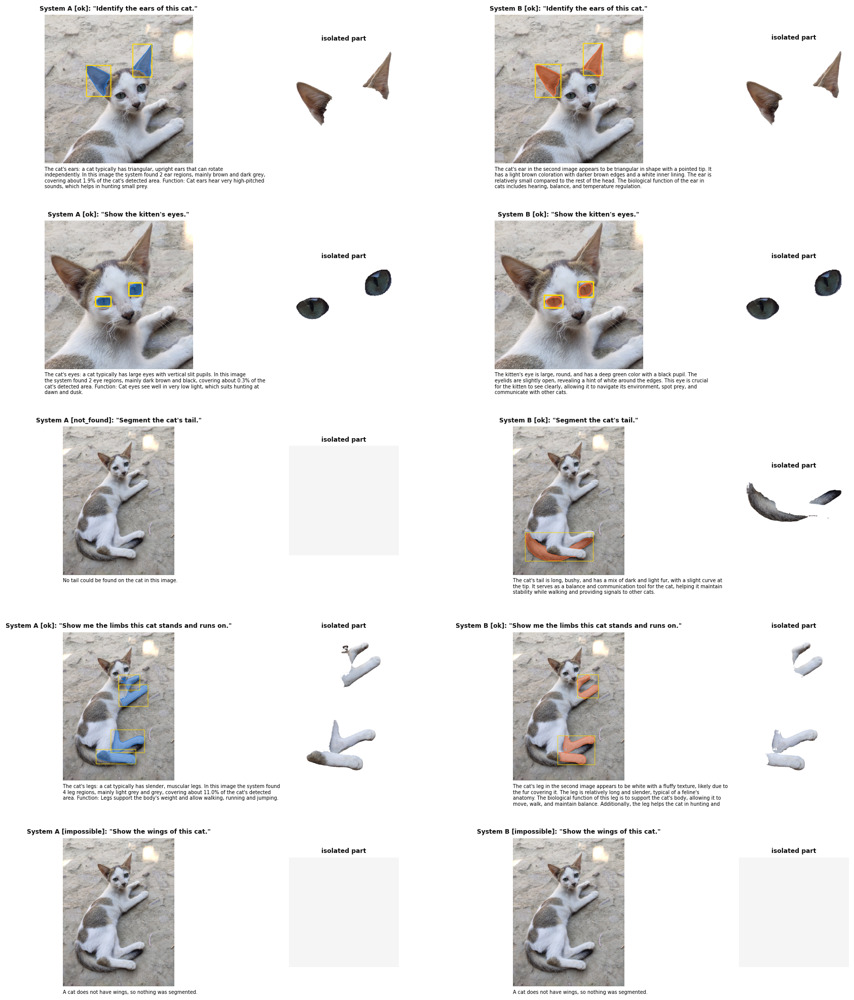

saved -> outputs\figures\fig15_phone_5.png


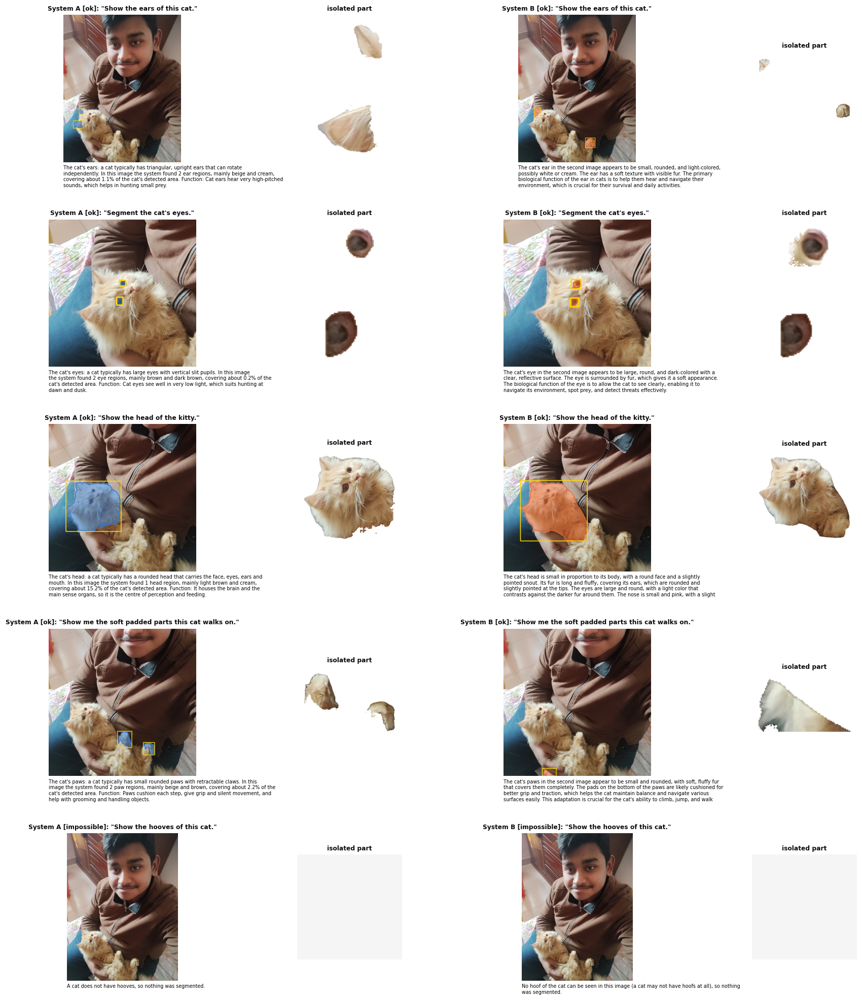

In [34]:
def view_box(results, H, W, min_frac=0.45):
    # common zoom window for both systems: around their masks and boxes, at least min_frac of the image
    xs, ys = [], []
    for res in results:
        if res["mask"].any():
            yy, xx = np.where(res["mask"]); xs += [xx.min(), xx.max()]; ys += [yy.min(), yy.max()]
        for b in res["boxes"]:
            xs += [b[0], b[2]]; ys += [b[1], b[3]]
    if not xs:
        return 0, 0, W, H
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    side = max(max(xs) - min(xs), max(ys) - min(ys)) * 2.2
    side = min(max(side, min_frac * min(H, W)), max(H, W))
    x1, y1 = int(np.clip(cx - side / 2, 0, max(0, W - side))), int(np.clip(cy - side / 2, 0, max(0, H - side)))
    return x1, y1, int(min(W, x1 + side)), int(min(H, y1 + side))

for img_name, g in PHONE_DF.groupby("image"):
    fig, axes = plt.subplots(len(g), 4, figsize=(15, 3.6 * len(g)), gridspec_kw={"width_ratios": [1, 0.6, 1, 0.6]})
    for row, r in enumerate(g.itertuples()):
        ra, rb = PH_RES[(r.qid, "A")], PH_RES[(r.qid, "B")]
        H, W = ra["image"].shape[:2]
        x1, y1, x2, y2 = view_box([ra, rb], H, W)
        for k, (tag, res) in enumerate((("A", ra), ("B", rb))):
            ov = overlay(res["image"], res["mask"], colour=(42, 120, 214) if tag == "A" else (235, 104, 52), boxes=res["boxes"])
            axes[row, 2 * k].imshow(ov[y1:y2, x1:x2])
            d = res.get("description", "") or ""
            axes[row, 2 * k].set_title(f"System {tag} [{res['status']}]: \"{r.prompt}\"", fontsize=8)
            axes[row, 2 * k].text(0.0, -0.02, "\n".join(textwrap.wrap(d, 90)[:4]), transform=axes[row, 2 * k].transAxes,
                                   fontsize=6.3, va="top")
            part = isolate(res["image"], res["mask"]) if res["mask"].any() else np.full((32, 32, 3), 245, np.uint8)
            axes[row, 2 * k + 1].imshow(part); axes[row, 2 * k + 1].set_title("isolated part", fontsize=8)
        for a in axes[row]: a.axis("off")
    plt.tight_layout(h_pad=3.2); savefig(fig, f"fig15_phone_{img_name[:-4]}.png"); plt.show()

In [35]:
# visual verdicts for the phone prompts (no ground-truth masks exist for these photos).
# correct = the requested part is segmented; partial = part found but mask incomplete or with spill-over;
# wrong = another part / region; missed = nothing returned although the part is visible;
# correct reject / false accept = behaviour on impossible prompts.
jfile = RES / "phone_judgements.csv"
if jfile.exists():
    J = pd.read_csv(jfile)
    J["score"] = J.verdict.map({"correct": 1, "correct reject": 1, "partial": 0.5}).fillna(0)
    summ = J.pivot_table(index="system", columns="style", values="score", aggfunc="mean").round(2)
    summ["overall"] = J.groupby("system").score.mean().round(2)
    display(summ); display(pd.crosstab(J.system, J.verdict))
    summ.to_csv(RES / "phone_prompt_following.csv")
else:
    print("phone_judgements.csv not written yet -- inspect fig15_phone_*.png and fill it in")

style,direct,impossible,indirect,synonym,overall
system,,,,,
A,0.8,1.0,0.6,1.0,0.84
B,0.9,1.0,0.8,0.9,0.90


verdict,correct,correct reject,missed,partial,wrong
system,,,,,
A,15,5,1,2,2
B,16,5,0,3,1


---
# 8. Summary

In [36]:
summary = pd.DataFrame({
    "interpretation accuracy": pf["interpretation acc. (all prompts)"],
    "correct-part rate": pf["correct-part rate (positive prompts)"],
    "rejection of impossible prompts": pf["rejection rate (impossible prompts)"],
    "mean IoU": SEG["IoU"], "mean Dice": SEG["Dice"],
}).loc[order].round(3)
summary.loc["A", "description score (0-5)"] = desc.loc["A", "score"]; summary.loc["B", "description score (0-5)"] = desc.loc["B", "score"]
summary.loc["A", "s / query"] = COMP.loc["A", "per prompt, no description (s)"] + COMP.loc["A", "description (s)"]
summary.loc["B", "s / query"] = COMP.loc["B", "per prompt, no description (s)"] + COMP.loc["B", "description (s)"]
summary.loc["A", "params (M)"] = COMP.loc["A", "parameters (M)"]; summary.loc["B", "params (M)"] = COMP.loc["B", "parameters (M)"]
display(summary); summary.to_csv(RES / "summary.csv")
json.dump({"summary": summary.reset_index().to_dict("records"), "load": LOAD}, open(RES / "summary.json", "w"), indent=1, default=float)
print("figures:", len(list(FIG.glob("*.png"))), "| result files:", len(list(RES.glob("*"))))

,interpretation accuracy,correct-part rate,rejection of impossible prompts,mean IoU,mean Dice,description score (0-5),s / query,params (M)
system,,,,,,,,
A,0.950,0.714,1.000,0.510,0.598,4.317,0.124,133.728
A / YOLO-seg masks,0.950,0.733,1.000,0.471,0.570,NaN,NaN,NaN
B,0.972,0.686,0.925,0.441,0.545,4.483,7.013,4067.786
B / VLM boxes only,0.972,0.692,0.925,0.441,0.545,NaN,NaN,NaN
B / DINO boxes only,0.972,0.183,0.950,0.163,0.210,NaN,NaN,NaN
B / never reject on visibility,0.920,0.692,0.400,0.445,0.551,NaN,NaN,NaN
B / reject if not visible,0.972,0.628,0.925,0.404,0.498,NaN,NaN,NaN


figures: 19 | result files: 24


## 8.1 Main findings

| | System A (no VLM) | System B (VLM) |
|---|---|---|
| prompt interpretation (PASCAL-Part, 400 prompts) | 95.0% | **97.2%** |
| … on indirect prompts (*"the part it uses to smell"*) | 83.3% | **98.3%** |
| … on synonym prompts | **100%** | 95.0% |
| impossible requests refused | **100%** | 92.5% |
| real parts wrongly refused | **0.8%** | 3.1% |
| correct-part rate (positive prompts) | **71.4%** | 68.6% |
| mean IoU / Dice | **0.510 / 0.598** | 0.441 / 0.545 |
| phone photos, visual verdict (25 prompts) | 0.84 | **0.90** |
| description checklist score (0–5) | 4.32 | **4.48** |
| similarity of same-part descriptions (lower = more image-specific) | 0.88 | **0.77** |
| time per query (with description) | **0.12 s** | 7.0 s |
| parameters / GPU weights | **134 M / 0.55 GB** | 4 068 M / 7.9 GB |

**Prompt interpretation.** The VLM understands the request better wherever understanding is hard. On indirect
prompts it is right 98% of the time against 83% for the keyword-plus-embedding parser, whose typical failure is
being misled by another part named in the sentence (*"the part that joins its head to its body"* → head). On the
phone photos the same pattern holds: System A segments the muzzle for *"the part this dog sees with"* and the whole
body for *"the part at the back end that this dog wags"*, while System B finds the eyes and the tail. System A's
perfect score on synonyms reflects a hand-written lexicon that already contains the common synonyms. It would fail
on any wording outside that list.

**Segmentation.** On PASCAL-Part, System A segments better (IoU 0.51 against 0.44). It is a *specialist*: its part
detector was trained on PASCAL-Part, so its boxes follow the dataset's own part boundaries. This shows most on large
parts whose extent is a matter of convention (head 0.82 vs 0.57, torso 0.65 vs 0.33). System B is better on parts that
are rare in the training data, such as beaks, wings, feet, horns and tails, and on birds overall (0.41 vs 0.20), where the
specialist had too few examples. On the phone photos, which are out of domain for System A, System B is slightly
better. Its errors there are incomplete coverage of legs and paws; System A's are interpretation errors and one
missed tail.

**Localisation inside System B.** Qwen2.5-VL's own boxes carry almost all of System B's accuracy (IoU 0.441 with
fusion, 0.441 with VLM boxes alone). Grounding DINO used alone reaches only 0.16, because for phrases such as *"dog
ear"* it often returns the whole animal or the wrong part. In the fusion it slightly tightens boxes but does not change
the overall result.

**Refusing impossible requests.** System A's species–part ontology refuses every impossible request. The 3B VLM's
own *possible* flag catches only 40%. Combining it with the visibility flag and a text-only anatomy question raises
this to 92.5% at the cost of wrongly refusing 3.1% of real parts.

**Descriptions.** System A's predefined descriptions are always factually safe, and when it finds the part, its
measured colour is right 96% of the time. However, it says almost the same thing for every image (similarity 0.88), and
when its detector misses the part (22% of the described prompts) there is no description at all. System B
describes what is actually visible (eye colour, an open eyelid, a bushy tail with a white tip) and always states a
function. Its colour words are right less often (66%), and it occasionally adds dubious functions, such as a tail
helping a dog *"detect scents"*.

**Cost.** System A answers in about 0.12 s with 0.55 GB of GPU memory. System B needs about 7 s and 7.9 GB, and most
of that time is spent generating text (understanding, grounding and the description).

## 8.2 Suitability

* **System A** suits a *closed* set of animals and parts that has been labelled in advance, where speed, memory and
  predictable behaviour matter: a fast, cheap specialist. It needs labelled part masks for every new species or part,
  and its language understanding is limited to the words its designer anticipated.
* **System B** suits *open-ended* use: arbitrary wording, species and parts it was never trained for, and descriptions
  that refer to the actual image. It costs about 60 times more time per query, needs a large GPU, and its zero-shot boxes
  are less precise than those of a specialist trained on the target data.
* **Answer to the assignment's question.** Integrating a VLM clearly improves **prompt interpretation** (especially
  indirect wording) and **description generation**. It improves **body-part identification** on out-of-domain photos
  and rare parts, but not on in-domain data, where a supervised part detector with SAM 2 segments more accurately. A
  practical hybrid would let the VLM interpret the prompt and write the description while a specialist detector
  localises the part whenever the species and part are covered by its training data.

*Limitations of this evaluation:* IoU and Dice are measured on PASCAL-Part, which is System A's training domain. The
phone photos have no ground-truth masks and were judged by visual inspection, with the verdicts and notes in
`outputs/results/phone_judgements.csv`. The description checklist is automatic, so it rewards System A's templated
wording. The VLM is the 3B model because the 7B model does not fit in 16 GB alongside the other models.